In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
project_folder = Path.cwd().parent
data_folder = project_folder / "Data"
output_data_folder = data_folder / "outputs"

# Load IPL dataset
file_path = output_data_folder / "ipl_all_matches_with_metadata.csv"

ipl = pd.read_csv(file_path)

# Convert date column
ipl["date"] = pd.to_datetime(ipl["date"])

print("Dataset loaded successfully!")
print("Dataset shape:", ipl.shape)

display(ipl.head())

Dataset loaded successfully!
Dataset shape: (295732, 34)


C:\Users\sanik\AppData\Local\Temp\ipykernel_11296\2051006472.py:14: DtypeWarning: Columns (17,19,20,23) have mixed types. Specify dtype option on import or set low_memory=False.
  ipl = pd.read_csv(file_path)


,record_type,innings,delivery_number,batting_team,batter,non_striker,bowler,batter_runs,total_extras,wides,...,date,match_type,venue,city,toss_winner,toss_decision,winner,winner_runs,winner_wickets,player_of_match
0,ball,1,0.1,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017-04-05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
1,ball,1,0.2,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017-04-05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
2,ball,1,0.3,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,4,0,NaN,...,2017-04-05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
3,ball,1,0.4,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017-04-05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
4,ball,1,0.5,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,2,2.0,...,2017-04-05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh


In [2]:
print("Dataset shape:", ipl.shape)

print("\nColumn names:")
print(ipl.columns.tolist())

print("\nMissing values in important columns:")
important_columns = [
    "match_id", "season", "date", "innings",
    "batting_team", "batter", "bowler",
    "batter_runs", "venue", "delivery_number"
]

display(ipl[important_columns].isnull().sum())



Dataset shape: (295732, 34)

Column names:
['record_type', 'innings', 'delivery_number', 'batting_team', 'batter', 'non_striker', 'bowler', 'batter_runs', 'total_extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty_runs', 'dismissal_method', 'dismissed_players', 'actual_delivery', 'non_boundary', 'fielder_1', 'fielder_2', 'fielder_3', 'source_file', 'match_id', 'season', 'date', 'match_type', 'venue', 'city', 'toss_winner', 'toss_decision', 'winner', 'winner_runs', 'winner_wickets', 'player_of_match']

Missing values in important columns:


match_id           0
season             0
date               0
innings            0
batting_team       0
batter             0
bowler             0
batter_runs        0
venue              0
delivery_number    0
dtype: int64

In [3]:
# Convert season values to strings
ipl["season"] = ipl["season"].astype(str)

# Display seasons in chronological order
available_seasons = sorted(ipl["season"].unique())

print("Available IPL seasons:")
print(available_seasons)

print("\nTotal seasons:", len(available_seasons))

print("\nSeason data type:", ipl["season"].dtype)

Available IPL seasons:
['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022', '2023', '2024', '2025', '2026']

Total seasons: 19

Season data type: object


In [4]:
print("Sample delivery numbers:")
print(
    ipl[["innings", "delivery_number", "batter", "bowler"]]
    .head(25)
    .to_string(index=False)
)

print("\nDelivery number statistics:")
display(ipl["delivery_number"].describe())

print("\nUnique delivery numbers (first 30):")
print(sorted(ipl["delivery_number"].unique())[:30])

Sample delivery numbers:
 innings  delivery_number       batter      bowler
       1              0.1    DA Warner    TS Mills
       1              0.2    DA Warner    TS Mills
       1              0.3    DA Warner    TS Mills
       1              0.4    DA Warner    TS Mills
       1              0.5    DA Warner    TS Mills
       1              0.6     S Dhawan    TS Mills
       1              0.7     S Dhawan    TS Mills
       1              1.1     S Dhawan A Choudhary
       1              1.2    DA Warner A Choudhary
       1              1.3    DA Warner A Choudhary
       1              1.4    DA Warner A Choudhary
       1              1.5    DA Warner A Choudhary
       1              1.6 MC Henriques A Choudhary
       1              1.7 MC Henriques A Choudhary
       1              2.1     S Dhawan    TS Mills
       1              2.2 MC Henriques    TS Mills
       1              2.3 MC Henriques    TS Mills
       1              2.4 MC Henriques    TS Mills
      

count    295732.000000
mean          9.553099
std           5.682519
min           0.100000
25%           4.500000
50%           9.400000
75%          14.400000
max          19.900000
Name: delivery_number, dtype: float64


Unique delivery numbers (first 30):
[np.float64(0.1), np.float64(0.11), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.1), np.float64(1.2), np.float64(1.3), np.float64(1.4), np.float64(1.5), np.float64(1.6), np.float64(1.7), np.float64(1.8), np.float64(1.9), np.float64(2.1), np.float64(2.2), np.float64(2.3), np.float64(2.4), np.float64(2.5), np.float64(2.6), np.float64(2.7), np.float64(2.8), np.float64(2.9), np.float64(3.1), np.float64(3.11)]


In [5]:
# Extract completed-over index from delivery number
ipl["over_number"] = np.floor(
    ipl["delivery_number"]
).astype(int)

# Assign batting phases
def assign_phase(over):
    if 0 <= over <= 5:
        return "Powerplay"
    elif 6 <= over <= 14:
        return "Middle"
    elif 15 <= over <= 19:
        return "Death"
    else:
        return "Other"

ipl["phase"] = ipl["over_number"].apply(assign_phase)

print("Phase assignment completed!")

print("\nOver and phase examples:")
display(
    ipl[["delivery_number", "over_number", "phase"]]
    .drop_duplicates()
    .sort_values("delivery_number")
    .head(25)
)

print("\nDelivery count by phase:")
display(ipl["phase"].value_counts())

Phase assignment completed!

Over and phase examples:


,delivery_number,over_number,phase
0,0.10,0,Powerplay
153534,0.11,0,Powerplay
1,0.20,0,Powerplay
2,0.30,0,Powerplay
3,0.40,0,Powerplay
4,0.50,0,Powerplay
5,0.60,0,Powerplay
6,0.70,0,Powerplay
1431,0.80,0,Powerplay
28370,0.90,0,Powerplay



Delivery count by phase:


phase
Middle       135655
Powerplay     92904
Death         67173
Name: count, dtype: int64

In [6]:
# Create a copy for batting analysis
batting_data = ipl.copy()

# Balls faced: exclude wides
batting_data["balls_faced"] = (
    batting_data["wides"].fillna(0) == 0
).astype(int)

# Boundary runs
batting_data["boundary_runs"] = np.where(
    batting_data["batter_runs"].isin([4, 6]),
    batting_data["batter_runs"],
    0
)

# Boundary count
batting_data["boundaries"] = (
    batting_data["batter_runs"].isin([4, 6])
).astype(int)

# Group by batter and phase
phase_batting = (
    batting_data.groupby(["batter", "phase"])
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        boundaries=("boundaries", "sum"),
        boundary_runs=("boundary_runs", "sum")
    )
    .reset_index()
)

# Calculate dismissals credited to the batter
batting_dismissals = (
    batting_data[
        batting_data["dismissal_method"].isin(
            ["bowled", "caught", "caught and bowled",
             "lbw", "stumped", "hit wicket", "hit the ball twice",
             "obstructing the field"]
        )
    ]
    .groupby(["batter", "phase"])
    .size()
    .reset_index(name="dismissals")
)

phase_batting = phase_batting.merge(
    batting_dismissals,
    on=["batter", "phase"],
    how="left"
)

phase_batting["dismissals"] = (
    phase_batting["dismissals"].fillna(0).astype(int)
)

# Batting average and strike rate
phase_batting["batting_average"] = (
    phase_batting["total_runs"] /
    phase_batting["dismissals"].replace(0, np.nan)
)

phase_batting["strike_rate"] = (
    phase_batting["total_runs"] /
    phase_batting["balls_faced"].replace(0, np.nan) * 100
)

phase_batting["boundary_percentage"] = (
    phase_batting["boundaries"] /
    phase_batting["balls_faced"].replace(0, np.nan) * 100
)

print("Phase-wise batting table created!")
print("Shape:", phase_batting.shape)

display(
    phase_batting.sort_values(
        ["phase", "total_runs"],
        ascending=[True, False]
    ).head(15)
)

Phase-wise batting table created!
Shape: (1620, 10)


,batter,phase,total_runs,balls_faced,boundaries,boundary_runs,dismissals,batting_average,strike_rate,boundary_percentage
894,MS Dhoni,Death,3468,1982,460,2256,93,37.290323,174.974773,23.208880
651,KA Pollard,Death,2032,1194,273,1380,75,27.093333,170.184255,22.864322
1136,RA Jadeja,Death,1922,1280,224,1062,75,25.626667,150.156250,17.500000
663,KD Karthik,Death,1904,1098,270,1278,74,25.729730,173.406193,24.590164
69,AB de Villiers,Death,1868,838,275,1380,34,54.941176,222.911695,32.816229
1519,V Kohli,Death,1573,835,212,1034,57,27.596491,188.383234,25.389222
1156,RG Sharma,Death,1527,843,220,1066,58,26.327586,181.138790,26.097272
501,HH Pandya,Death,1510,895,204,1012,62,24.354839,168.715084,22.793296
342,DA Miller,Death,1509,866,196,974,48,31.437500,174.249423,22.632794
92,AD Russell,Death,1432,731,227,1164,51,28.078431,195.896033,31.053352


In [7]:
print("Dismissal methods:")
display(
    ipl["dismissal_method"]
    .value_counts(dropna=False)
)

print("\nDismissal examples:")
display(
    ipl.loc[
        ipl["dismissal_method"].notna(),
        [
            "batter",
            "dismissed_players",
            "dismissal_method",
            "non_boundary",
            "batter_runs"
        ]
    ].head(15)
)

print("\nNon-boundary values:")
display(ipl["non_boundary"].value_counts(dropna=False))

Dismissal methods:


dismissal_method
NaN                      281027
caught                     9321
bowled                     2460
run out                    1194
lbw                         883
caught and bowled           410
stumped                     388
hit wicket                   20
retired hurt                 19
retired out                   6
obstructing the field         4
Name: count, dtype: int64


Dismissal examples:


,batter,dismissed_players,dismissal_method,non_boundary,batter_runs
11,DA Warner,DA Warner,caught,NaN,0
64,S Dhawan,S Dhawan,caught,NaN,0
94,MC Henriques,MC Henriques,caught,NaN,0
116,Yuvraj Singh,Yuvraj Singh,bowled,NaN,0
160,Mandeep Singh,Mandeep Singh,bowled,NaN,0
165,CH Gayle,CH Gayle,caught,NaN,0
199,KM Jadhav,KM Jadhav,run out,NaN,1
206,TM Head,TM Head,caught,NaN,0
211,Sachin Baby,Sachin Baby,caught,NaN,0
230,STR Binny,STR Binny,caught,NaN,0



Non-boundary values:


non_boundary
NaN     295703
True        29
Name: count, dtype: int64

In [8]:
# Deliveries where dismissed player differs from batter
different_dismissals = ipl[
    ipl["dismissed_players"].notna() &
    (ipl["dismissed_players"] != ipl["batter"])
]

print("Dismissals where batter and dismissed player differ:")
print("Total records:", len(different_dismissals))

display(
    different_dismissals[
        [
            "batter",
            "dismissed_players",
            "dismissal_method",
            "phase",
            "match_id"
        ]
    ].head(15)
)

print("\nNon-boundary records:")
display(
    ipl.loc[
        ipl["non_boundary"] == True,
        [
            "batter",
            "batter_runs",
            "non_boundary",
            "phase",
            "match_id"
        ]
    ]
)

Dismissals where batter and dismissed player differ:
Total records: 571


,batter,dismissed_players,dismissal_method,phase,match_id
247,A Choudhary,YS Chahal,run out,Death,1082591
371,HH Pandya,TG Southee,run out,Death,1082592
2700,P Negi,KM Jadhav,run out,Death,1082602
4989,SV Samson,KK Nair,run out,Middle,1082611
5399,YK Pathan,SA Yadav,run out,Death,1082613
5546,N Rana,JC Buttler,run out,Powerplay,1082614
5632,HH Pandya,Harbhajan Singh,run out,Death,1082614
5966,MS Dhoni,RA Tripathi,run out,Middle,1082615
6680,Harbhajan Singh,MJ McClenaghan,run out,Death,1082618
6823,G Gambhir,SP Narine,run out,Powerplay,1082620



Non-boundary records:


,batter,batter_runs,non_boundary,phase,match_id
918,GJ Maxwell,4,True,Middle,1082594
2477,MM Sharma,4,True,Death,1082601
18490,KS Williamson,4,True,Middle,1136580
41228,N Pooran,4,True,Middle,1178430
53937,RR Pant,4,True,Death,1216539
56574,S Dhawan,6,True,Middle,1237180
58943,F du Plessis,4,True,Middle,1254065
76043,D Padikkal,4,True,Powerplay,1304066
78530,JC Buttler,4,True,Powerplay,1304076
84627,DP Conway,4,True,Middle,1304101


In [9]:
# Create a fresh batting dataset
batting_data = ipl.copy()

# Balls faced: exclude wides
batting_data["balls_faced"] = (
    batting_data["wides"].fillna(0) == 0
).astype(int)

# Actual boundaries: exclude non-boundary hits
batting_data["boundaries"] = (
    batting_data["batter_runs"].isin([4, 6]) &
    (batting_data["non_boundary"] != True)
).astype(int)

# Runs scored from actual boundaries
batting_data["boundary_runs"] = np.where(
    batting_data["boundaries"] == 1,
    batting_data["batter_runs"],
    0
)

# Aggregate batting performance
phase_batting_corrected = (
    batting_data.groupby(["batter", "phase"])
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        boundaries=("boundaries", "sum"),
        boundary_runs=("boundary_runs", "sum")
    )
    .reset_index()
)

# Correct dismissal attribution
dismissal_methods = [
    "caught",
    "bowled",
    "run out",
    "lbw",
    "caught and bowled",
    "stumped",
    "hit wicket",
    "retired out",
    "obstructing the field"
]

dismissal_data = batting_data[
    batting_data["dismissal_method"].isin(dismissal_methods)
].copy()

# Use dismissed_players where available
dismissal_data["dismissed_batter"] = (
    dismissal_data["dismissed_players"]
    .fillna(dismissal_data["batter"])
)

batting_dismissals_corrected = (
    dismissal_data.groupby(["dismissed_batter", "phase"])
    .size()
    .reset_index(name="dismissals")
    .rename(columns={"dismissed_batter": "batter"})
)

# Merge dismissal counts
phase_batting_corrected = phase_batting_corrected.merge(
    batting_dismissals_corrected,
    on=["batter", "phase"],
    how="left"
)

phase_batting_corrected["dismissals"] = (
    phase_batting_corrected["dismissals"].fillna(0).astype(int)
)

# Calculate traditional batting metrics
phase_batting_corrected["batting_average"] = (
    phase_batting_corrected["total_runs"] /
    phase_batting_corrected["dismissals"].replace(0, np.nan)
)

phase_batting_corrected["strike_rate"] = (
    phase_batting_corrected["total_runs"] /
    phase_batting_corrected["balls_faced"].replace(0, np.nan) * 100
)

phase_batting_corrected["boundary_percentage"] = (
    phase_batting_corrected["boundaries"] /
    phase_batting_corrected["balls_faced"].replace(0, np.nan) * 100
)

print("Corrected phase-wise batting statistics created!")
print("Shape:", phase_batting_corrected.shape)

display(
    phase_batting_corrected.sort_values(
        ["phase", "total_runs"],
        ascending=[True, False]
    ).head(15)
)

Corrected phase-wise batting statistics created!
Shape: (1620, 10)


,batter,phase,total_runs,balls_faced,boundaries,boundary_runs,dismissals,batting_average,strike_rate,boundary_percentage
894,MS Dhoni,Death,3468,1982,460,2256,99,35.030303,174.974773,23.208880
651,KA Pollard,Death,2032,1194,273,1380,80,25.400000,170.184255,22.864322
1136,RA Jadeja,Death,1922,1280,224,1062,81,23.728395,150.156250,17.500000
663,KD Karthik,Death,1904,1098,270,1278,82,23.219512,173.406193,24.590164
69,AB de Villiers,Death,1868,838,275,1380,42,44.476190,222.911695,32.816229
1519,V Kohli,Death,1573,835,212,1034,60,26.216667,188.383234,25.389222
1156,RG Sharma,Death,1527,843,220,1066,62,24.629032,181.138790,26.097272
501,HH Pandya,Death,1510,895,203,1006,65,23.230769,168.715084,22.681564
342,DA Miller,Death,1509,866,196,974,49,30.795918,174.249423,22.632794
92,AD Russell,Death,1432,731,227,1164,58,24.689655,195.896033,31.053352


In [10]:
minimum_balls = 100

for phase_name in ["Powerplay", "Middle", "Death"]:

    phase_data = phase_batting_corrected[
        (phase_batting_corrected["phase"] == phase_name) &
        (phase_batting_corrected["balls_faced"] >= minimum_balls)
    ]

    top_batters = phase_data.sort_values(
        "strike_rate",
        ascending=False
    ).head(10)

    print(f"\nTop 10 Batters in {phase_name} (by Strike Rate)")
    display(
        top_batters[
            [
                "batter",
                "total_runs",
                "balls_faced",
                "batting_average",
                "strike_rate",
                "boundary_percentage"
            ]
        ].round(2)
    )


Top 10 Batters in Powerplay (by Strike Rate)


,batter,total_runs,balls_faced,batting_average,strike_rate,boundary_percentage
1534,V Suryavanshi,665,293,60.45,226.96,40.61
551,J Fraser-McGurk,298,144,27.09,206.94,39.58
621,JP Inglis,307,155,61.40,198.06,34.84
1080,Priyansh Arya,678,355,30.82,190.99,32.68
24,A Mhatre,275,145,30.56,189.66,36.55
450,FH Allen,207,113,23.00,183.19,34.51
1491,TM Head,1010,568,42.08,177.82,32.57
1035,PD Salt,840,488,38.18,172.13,29.51
163,Abhishek Sharma,1387,807,38.53,171.87,29.24
1349,SP Narine,1174,690,23.02,170.14,31.16



Top 10 Batters in Middle (by Strike Rate)


,batter,total_runs,balls_faced,batting_average,strike_rate,boundary_percentage
1533,V Suryavanshi,334,146,30.36,228.77,36.30
1079,Priyansh Arya,231,116,25.67,199.14,29.31
1148,RD Rickelton,258,141,25.80,182.98,26.24
1034,PD Salt,383,214,27.36,178.97,25.70
162,Abhishek Sharma,796,455,23.41,174.95,23.52
1348,SP Narine,486,279,15.19,174.19,26.88
1527,V Sehwag,1062,615,31.24,172.68,24.55
1175,RM Patidar,1102,641,40.81,171.92,21.22
1016,P Simran Singh,634,392,22.64,161.73,21.43
269,C Connolly,260,161,37.14,161.49,21.74



Top 10 Batters in Death (by Strike Rate)


,batter,total_runs,balls_faced,batting_average,strike_rate,boundary_percentage
69,AB de Villiers,1868,838,44.48,222.91,32.82
763,LS Livingstone,345,159,23.00,216.98,32.70
1174,RM Patidar,267,124,16.69,215.32,33.87
227,B Sai Sudharsan,308,149,22.00,206.71,30.20
808,MA Agarwal,252,122,21.00,206.56,29.51
1081,Q de Kock,240,117,30.00,205.13,31.62
293,CH Gayle,581,284,36.31,204.58,31.34
1184,RR Pant,1095,540,25.47,202.78,31.48
1466,T Stubbs,546,275,49.64,198.55,27.64
1502,Tilak Varma,543,274,25.86,198.18,29.56


In [11]:
phase_baseline = (
    phase_batting_corrected
    .groupby("phase")
    .agg(
        total_runs=("total_runs", "sum"),
        total_balls=("balls_faced", "sum"),
        total_dismissals=("dismissals", "sum"),
        total_boundaries=("boundaries", "sum")
    )
    .reset_index()
)

phase_baseline["league_batting_average"] = (
    phase_baseline["total_runs"] /
    phase_baseline["total_dismissals"].replace(0, np.nan)
)

phase_baseline["league_strike_rate"] = (
    phase_baseline["total_runs"] /
    phase_baseline["total_balls"] * 100
)

phase_baseline["league_boundary_percentage"] = (
    phase_baseline["total_boundaries"] /
    phase_baseline["total_balls"] * 100
)

print("IPL Phase-wise Batting Baselines")

display(
    phase_baseline[
        [
            "phase",
            "total_runs",
            "total_balls",
            "league_batting_average",
            "league_strike_rate",
            "league_boundary_percentage"
        ]
    ].round(2)
)

IPL Phase-wise Batting Baselines


,phase,total_runs,total_balls,league_batting_average,league_strike_rate,league_boundary_percentage
0,Death,101284,64280,18.84,157.57,20.59
1,Middle,166711,131891,29.23,126.40,14.21
2,Powerplay,113534,89685,31.48,126.59,20.31


In [12]:
# Attach phase-wise league baselines to each batter
batting_relative = phase_batting_corrected.merge(
    phase_baseline[
        [
            "phase",
            "league_batting_average",
            "league_strike_rate",
            "league_boundary_percentage"
        ]
    ],
    on="phase",
    how="left"
)

# Calculate percentage advantage over the phase baseline
batting_relative["strike_rate_advantage"] = (
    (batting_relative["strike_rate"] /
     batting_relative["league_strike_rate"]) - 1
) * 100

batting_relative["average_advantage"] = (
    (batting_relative["batting_average"] /
     batting_relative["league_batting_average"]) - 1
) * 100

batting_relative["boundary_advantage"] = (
    (batting_relative["boundary_percentage"] /
     batting_relative["league_boundary_percentage"]) - 1
) * 100

print("Phase-relative batting performance calculated!")
print("Shape:", batting_relative.shape)

# Display the top 10 batters by strike-rate advantage in each phase
for phase_name in ["Powerplay", "Middle", "Death"]:

    print(f"\nTop 10 {phase_name} Batters by Strike-Rate Advantage")

    top_players = batting_relative[
        (batting_relative["phase"] == phase_name) &
        (batting_relative["balls_faced"] >= 100)
    ].sort_values(
        "strike_rate_advantage",
        ascending=False
    ).head(10)

    display(
        top_players[
            [
                "batter",
                "balls_faced",
                "strike_rate",
                "league_strike_rate",
                "strike_rate_advantage",
                "average_advantage",
                "boundary_advantage"
            ]
        ].round(2)
    )

Phase-relative batting performance calculated!
Shape: (1620, 16)

Top 10 Powerplay Batters by Strike-Rate Advantage


,batter,balls_faced,strike_rate,league_strike_rate,strike_rate_advantage,average_advantage,boundary_advantage
1534,V Suryavanshi,293,226.96,126.59,79.29,92.01,99.97
551,J Fraser-McGurk,144,206.94,126.59,63.47,-13.96,94.90
621,JP Inglis,155,198.06,126.59,56.46,95.02,71.53
1080,Priyansh Arya,355,190.99,126.59,50.87,-2.12,60.89
24,A Mhatre,145,189.66,126.59,49.82,-2.95,79.97
450,FH Allen,113,183.19,126.59,44.71,-26.95,69.93
1491,TM Head,568,177.82,126.59,40.46,33.66,60.37
1035,PD Salt,488,172.13,126.59,35.97,21.27,45.29
163,Abhishek Sharma,807,171.87,126.59,35.77,22.37,43.99
1349,SP Narine,690,170.14,126.59,34.40,-26.89,53.42



Top 10 Middle Batters by Strike-Rate Advantage


,batter,balls_faced,strike_rate,league_strike_rate,strike_rate_advantage,average_advantage,boundary_advantage
1533,V Suryavanshi,146,228.77,126.4,80.99,3.87,155.39
1079,Priyansh Arya,116,199.14,126.4,57.55,-12.20,106.21
1148,RD Rickelton,141,182.98,126.4,44.76,-11.74,84.61
1034,PD Salt,214,178.97,126.4,41.59,-6.41,80.81
162,Abhishek Sharma,455,174.95,126.4,38.41,-19.91,65.45
1348,SP Narine,279,174.19,126.4,37.81,-48.05,89.12
1527,V Sehwag,615,172.68,126.4,36.62,6.85,72.74
1175,RM Patidar,641,171.92,126.4,36.01,39.62,49.27
1016,P Simran Singh,392,161.73,126.4,27.95,-22.54,50.76
269,C Connolly,161,161.49,126.4,27.76,27.06,52.94



Top 10 Death Batters by Strike-Rate Advantage


,batter,balls_faced,strike_rate,league_strike_rate,strike_rate_advantage,average_advantage,boundary_advantage
69,AB de Villiers,838,222.91,157.57,41.47,136.07,59.38
763,LS Livingstone,159,216.98,157.57,37.71,22.08,58.84
1174,RM Patidar,124,215.32,157.57,36.65,-11.43,64.51
227,B Sai Sudharsan,149,206.71,157.57,31.19,16.77,46.68
808,MA Agarwal,122,206.56,157.57,31.09,11.46,43.32
1081,Q de Kock,117,205.13,157.57,30.18,59.24,53.59
293,CH Gayle,284,204.58,157.57,29.84,92.74,52.20
1184,RR Pant,540,202.78,157.57,28.69,35.16,52.90
1466,T Stubbs,275,198.55,157.57,26.01,163.46,34.22
1502,Tilak Varma,274,198.18,157.57,25.77,37.25,43.58


In [13]:
# Compare player counts at different minimum-ball thresholds

sample_size_check = []

for phase_name in ["Powerplay", "Middle", "Death"]:

    phase_data = batting_relative[
        batting_relative["phase"] == phase_name
    ]

    for minimum_balls in [100, 200, 300, 500]:

        eligible_players = phase_data[
            phase_data["balls_faced"] >= minimum_balls
        ]

        sample_size_check.append({
            "phase": phase_name,
            "minimum_balls": minimum_balls,
            "eligible_players": len(eligible_players)
        })

sample_size_df = pd.DataFrame(sample_size_check)

print("Player Eligibility by Phase and Minimum Balls Faced")

display(
    sample_size_df.pivot(
        index="minimum_balls",
        columns="phase",
        values="eligible_players"
    )
)

Player Eligibility by Phase and Minimum Balls Faced


phase,Death,Middle,Powerplay
minimum_balls,,,
100,170,206,145
200,93,147,94
300,60,119,76
500,23,84,54


In [14]:
# Set minimum experience requirement
MINIMUM_BALLS = 200

# Keep only players who meet the threshold
eligible_batting = batting_relative[
    batting_relative["balls_faced"] >= MINIMUM_BALLS
].copy()

print("Eligible batting dataset created!")
print("Total batter-phase records:", len(eligible_batting))

print("\nEligible players in each phase:")

display(
    eligible_batting.groupby("phase")["batter"]
    .nunique()
    .reset_index(name="eligible_players")
)

print("\nSample records:")

display(
    eligible_batting[
        [
            "batter",
            "phase",
            "balls_faced",
            "strike_rate",
            "batting_average",
            "strike_rate_advantage",
            "average_advantage"
        ]
    ].head(10).round(2)
)

Eligible batting dataset created!
Total batter-phase records: 334

Eligible players in each phase:


,phase,eligible_players
0,Death,93
1,Middle,147
2,Powerplay,94



Sample records:


,batter,phase,balls_faced,strike_rate,batting_average,strike_rate_advantage,average_advantage
3,A Badoni,Death,327,164.53,22.42,4.42,18.98
4,A Badoni,Middle,410,125.85,30.35,-0.43,3.83
25,A Mishra,Death,250,104.00,9.63,-34.00,-48.89
36,A Raghuvanshi,Middle,330,140.91,35.77,11.48,22.36
41,A Symonds,Middle,484,125.83,40.60,-0.45,38.89
69,AB de Villiers,Death,838,222.91,44.48,41.47,136.07
70,AB de Villiers,Middle,1959,131.29,38.97,3.87,33.31
71,AB de Villiers,Powerplay,614,120.68,33.68,-4.67,6.98
75,AC Gilchrist,Middle,430,144.42,23.00,14.25,-21.32
76,AC Gilchrist,Powerplay,1033,134.08,28.85,5.91,-8.36


In [15]:
# Metrics that will contribute to the batting rating
rating_metrics = [
    "strike_rate_advantage",
    "average_advantage",
    "boundary_advantage"
]

# Check missing values
print("Missing values in rating metrics:")

display(
    eligible_batting[rating_metrics].isnull().sum()
)

# Check variation within each phase
print("\nMetric standard deviations by phase:")

display(
    eligible_batting.groupby("phase")[rating_metrics]
    .std()
    .round(2)
)

Missing values in rating metrics:


strike_rate_advantage    0
average_advantage        0
boundary_advantage       0
dtype: int64


Metric standard deviations by phase:


,strike_rate_advantage,average_advantage,boundary_advantage
phase,,,
Death,14.67,40.36,23.62
Middle,14.17,32.26,26.80
Powerplay,17.42,35.98,22.20


In [16]:
# Create a copy for standardized scoring
batting_rating_data = eligible_batting.copy()

# Standardize each metric within its phase
for metric in rating_metrics:

    phase_mean = (
        batting_rating_data.groupby("phase")[metric]
        .transform("mean")
    )

    phase_std = (
        batting_rating_data.groupby("phase")[metric]
        .transform("std")
    )

    batting_rating_data[f"{metric}_zscore"] = (
        (batting_rating_data[metric] - phase_mean) /
        phase_std
    )

print("Phase-wise standardized scores created!")

# Display standardized scores
display(
    batting_rating_data[
        [
            "batter",
            "phase",
            "strike_rate_advantage_zscore",
            "average_advantage_zscore",
            "boundary_advantage_zscore"
        ]
    ].head(10).round(2)
)

Phase-wise standardized scores created!


,batter,phase,strike_rate_advantage_zscore,average_advantage_zscore,boundary_advantage_zscore
3,A Badoni,Death,-0.04,-0.09,-0.34
4,A Badoni,Middle,-0.08,-0.13,-0.14
25,A Mishra,Death,-2.65,-1.77,-2.19
36,A Raghuvanshi,Middle,0.76,0.44,0.75
41,A Symonds,Middle,-0.09,0.95,-0.04
69,AB de Villiers,Death,2.49,2.82,2.26
70,AB de Villiers,Middle,0.22,0.78,-0.14
71,AB de Villiers,Powerplay,-0.38,-0.13,-0.32
75,AC Gilchrist,Middle,0.95,-0.91,1.16
76,AC Gilchrist,Powerplay,0.23,-0.55,0.50


In [17]:
# Calculate weighted Phase-Aware Batting Rating
batting_rating_data["batting_rating_raw"] = (
    0.40 * batting_rating_data["strike_rate_advantage_zscore"] +
    0.40 * batting_rating_data["average_advantage_zscore"] +
    0.20 * batting_rating_data["boundary_advantage_zscore"]
)

# Convert rating to a 0-100 scale
# 50 represents the average eligible batter in that phase
batting_rating_data["phase_aware_batting_rating"] = (
    50 + 10 * batting_rating_data["batting_rating_raw"]
)

print("Phase-Aware Batting Rating calculated!")

display(
    batting_rating_data[
        [
            "batter",
            "phase",
            "balls_faced",
            "batting_rating_raw",
            "phase_aware_batting_rating"
        ]
    ].sort_values(
        "phase_aware_batting_rating",
        ascending=False
    ).head(15).round(2)
)

Phase-Aware Batting Rating calculated!


,batter,phase,balls_faced,batting_rating_raw,phase_aware_batting_rating
1534,V Suryavanshi,Powerplay,293,3.54,85.41
69,AB de Villiers,Death,838,2.57,75.74
692,KP Pietersen,Powerplay,294,2.26,72.58
490,H Klaasen,Middle,795,2.25,72.54
398,DP Conway,Middle,342,2.22,72.20
1466,T Stubbs,Death,275,2.21,72.11
293,CH Gayle,Death,284,1.77,67.67
1175,RM Patidar,Middle,641,1.74,67.43
1491,TM Head,Powerplay,568,1.64,66.45
1416,Shashank Singh,Death,262,1.60,65.95


In [18]:
for phase_name in ["Powerplay", "Middle", "Death"]:

    phase_ranking = batting_rating_data[
        batting_rating_data["phase"] == phase_name
    ].sort_values(
        "phase_aware_batting_rating",
        ascending=False
    ).head(10)

    print(f"\nTop 10 Phase-Aware Batters — {phase_name}")

    display(
        phase_ranking[
            [
                "batter",
                "balls_faced",
                "total_runs",
                "batting_average",
                "strike_rate",
                "phase_aware_batting_rating"
            ]
        ].round(2).reset_index(drop=True)
    )


Top 10 Phase-Aware Batters — Powerplay


,batter,balls_faced,total_runs,batting_average,strike_rate,phase_aware_batting_rating
0,V Suryavanshi,293,665,60.45,226.96,85.41
1,KP Pietersen,294,392,98.00,133.33,72.58
2,TM Head,568,1010,42.08,177.82,66.45
3,Priyansh Arya,355,678,30.82,190.99,64.90
4,B Sai Sudharsan,737,1021,68.07,138.53,63.68
5,PD Salt,488,840,38.18,172.13,62.68
6,Abhishek Sharma,807,1387,38.53,171.87,62.64
7,RD Rickelton,343,554,42.62,161.52,61.26
8,YBK Jaiswal,1057,1680,40.00,158.94,60.60
9,JM Bairstow,625,944,47.20,151.04,60.23



Top 10 Phase-Aware Batters — Middle


,batter,balls_faced,total_runs,batting_average,strike_rate,phase_aware_batting_rating
0,H Klaasen,795,1256,62.80,157.99,72.54
1,DP Conway,342,521,65.12,152.34,72.20
2,RM Patidar,641,1102,40.81,171.92,67.43
3,PD Salt,214,383,27.36,178.97,65.65
4,SE Marsh,972,1448,49.93,148.97,65.29
5,V Sehwag,615,1062,31.24,172.68,65.29
6,CH Gayle,1288,2011,44.69,156.13,65.25
7,B Sai Sudharsan,800,1186,51.57,148.25,64.42
8,TH David,218,308,51.33,141.28,63.54
9,N Pooran,895,1420,34.63,158.66,62.09



Top 10 Phase-Aware Batters — Death


,batter,balls_faced,total_runs,batting_average,strike_rate,phase_aware_batting_rating
0,AB de Villiers,838,1868,44.48,222.91,75.74
1,T Stubbs,275,546,49.64,198.55,72.11
2,CH Gayle,284,581,36.31,204.58,67.67
3,Shashank Singh,262,512,39.38,195.42,65.95
4,RK Singh,417,791,37.67,189.69,64.75
5,RR Pant,540,1095,25.47,202.78,61.71
6,JC Buttler,417,804,30.92,192.81,61.05
7,Ashutosh Sharma,217,417,29.79,192.17,60.95
8,TH David,432,843,29.07,195.14,60.66
9,Tilak Varma,274,543,25.86,198.18,60.33


In [19]:
for phase_name in ["Powerplay", "Middle", "Death"]:

    phase_ranking = batting_rating_data[
        batting_rating_data["phase"] == phase_name
    ].sort_values(
        "phase_aware_batting_rating",
        ascending=False
    ).head(10)

    print(f"\nDismissal Reliability Check — {phase_name}")

    display(
        phase_ranking[
            [
                "batter",
                "total_runs",
                "balls_faced",
                "dismissals",
                "batting_average",
                "strike_rate",
                "phase_aware_batting_rating"
            ]
        ].round(2).reset_index(drop=True)
    )


Dismissal Reliability Check — Powerplay


,batter,total_runs,balls_faced,dismissals,batting_average,strike_rate,phase_aware_batting_rating
0,V Suryavanshi,665,293,11,60.45,226.96,85.41
1,KP Pietersen,392,294,4,98.00,133.33,72.58
2,TM Head,1010,568,24,42.08,177.82,66.45
3,Priyansh Arya,678,355,22,30.82,190.99,64.90
4,B Sai Sudharsan,1021,737,15,68.07,138.53,63.68
5,PD Salt,840,488,22,38.18,172.13,62.68
6,Abhishek Sharma,1387,807,36,38.53,171.87,62.64
7,RD Rickelton,554,343,13,42.62,161.52,61.26
8,YBK Jaiswal,1680,1057,42,40.00,158.94,60.60
9,JM Bairstow,944,625,20,47.20,151.04,60.23



Dismissal Reliability Check — Middle


,batter,total_runs,balls_faced,dismissals,batting_average,strike_rate,phase_aware_batting_rating
0,H Klaasen,1256,795,20,62.80,157.99,72.54
1,DP Conway,521,342,8,65.12,152.34,72.20
2,RM Patidar,1102,641,27,40.81,171.92,67.43
3,PD Salt,383,214,14,27.36,178.97,65.65
4,SE Marsh,1448,972,29,49.93,148.97,65.29
5,V Sehwag,1062,615,34,31.24,172.68,65.29
6,CH Gayle,2011,1288,45,44.69,156.13,65.25
7,B Sai Sudharsan,1186,800,23,51.57,148.25,64.42
8,TH David,308,218,6,51.33,141.28,63.54
9,N Pooran,1420,895,41,34.63,158.66,62.09



Dismissal Reliability Check — Death


,batter,total_runs,balls_faced,dismissals,batting_average,strike_rate,phase_aware_batting_rating
0,AB de Villiers,1868,838,42,44.48,222.91,75.74
1,T Stubbs,546,275,11,49.64,198.55,72.11
2,CH Gayle,581,284,16,36.31,204.58,67.67
3,Shashank Singh,512,262,13,39.38,195.42,65.95
4,RK Singh,791,417,21,37.67,189.69,64.75
5,RR Pant,1095,540,43,25.47,202.78,61.71
6,JC Buttler,804,417,26,30.92,192.81,61.05
7,Ashutosh Sharma,417,217,14,29.79,192.17,60.95
8,TH David,843,432,29,29.07,195.14,60.66
9,Tilak Varma,543,274,21,25.86,198.18,60.33


In [20]:
# Experimental reliability adjustment
PRIOR_DISMISSALS = 10

batting_rating_data["adjusted_batting_average"] = (
    batting_rating_data["total_runs"] +
    PRIOR_DISMISSALS * batting_rating_data["league_batting_average"]
) / (
    batting_rating_data["dismissals"] + PRIOR_DISMISSALS
)

# Recalculate average advantage using adjusted average
batting_rating_data["adjusted_average_advantage"] = (
    batting_rating_data["adjusted_batting_average"] /
    batting_rating_data["league_batting_average"] - 1
) * 100

# Standardize adjusted average advantage within each phase
phase_mean = batting_rating_data.groupby("phase")[
    "adjusted_average_advantage"
].transform("mean")

phase_std = batting_rating_data.groupby("phase")[
    "adjusted_average_advantage"
].transform("std")

batting_rating_data["adjusted_average_advantage_zscore"] = (
    batting_rating_data["adjusted_average_advantage"] - phase_mean
) / phase_std

# Calculate the revised rating
batting_rating_data["adjusted_batting_rating_raw"] = (
    0.40 * batting_rating_data["strike_rate_advantage_zscore"] +
    0.40 * batting_rating_data["adjusted_average_advantage_zscore"] +
    0.20 * batting_rating_data["boundary_advantage_zscore"]
)

batting_rating_data["reliability_adjusted_rating"] = (
    50 + 10 * batting_rating_data["adjusted_batting_rating_raw"]
)

print("Original and reliability-adjusted ratings:")
display(
    batting_rating_data[
        batting_rating_data["batter"].isin([
            "KP Pietersen", "DP Conway", "TH David",
            "T Stubbs", "AB de Villiers"
        ])
    ][
        [
            "batter", "phase", "dismissals",
            "batting_average", "adjusted_batting_average",
            "phase_aware_batting_rating",
            "reliability_adjusted_rating"
        ]
    ].round(2).sort_values(
        ["phase", "reliability_adjusted_rating"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

Original and reliability-adjusted ratings:


,batter,phase,dismissals,batting_average,adjusted_batting_average,phase_aware_batting_rating,reliability_adjusted_rating
0,AB de Villiers,Death,42,44.48,39.55,75.74,77.80
1,T Stubbs,Death,11,49.64,34.97,72.11,68.02
2,TH David,Death,29,29.07,26.45,60.66,61.00
3,DP Conway,Middle,8,65.12,45.18,72.20,67.30
4,TH David,Middle,6,51.33,37.52,63.54,59.54
5,AB de Villiers,Middle,66,38.97,37.69,53.72,55.08
6,KP Pietersen,Middle,21,23.14,25.11,46.56,46.50
7,T Stubbs,Middle,12,32.83,31.20,46.14,45.90
8,KP Pietersen,Powerplay,4,98.00,50.49,72.58,60.97
9,DP Conway,Powerplay,11,42.09,37.04,51.25,50.94


In [21]:
rating_comparison = batting_rating_data[
    ["batter", "phase", "phase_aware_batting_rating"]
].merge(
    batting_rating_data[
        ["batter", "phase", "reliability_adjusted_rating"]
    ],
    on=["batter", "phase"],
    how="inner"
)

rating_comparison["original_rank"] = (
    rating_comparison.groupby("phase")[
        "phase_aware_batting_rating"
    ].rank(ascending=False, method="min")
)

rating_comparison["adjusted_rank"] = (
    rating_comparison.groupby("phase")[
        "reliability_adjusted_rating"
    ].rank(ascending=False, method="min")
)

rating_comparison["rank_change"] = (
    rating_comparison["original_rank"] -
    rating_comparison["adjusted_rank"]
)

for phase_name in ["Powerplay", "Middle", "Death"]:

    print(f"\nRanking Changes — {phase_name}")

    phase_comparison = rating_comparison[
        rating_comparison["phase"] == phase_name
    ].sort_values("adjusted_rank").head(10)

    display(
        phase_comparison[
            [
                "batter",
                "phase_aware_batting_rating",
                "reliability_adjusted_rating",
                "original_rank",
                "adjusted_rank",
                "rank_change"
            ]
        ].round(2).reset_index(drop=True)
    )


Ranking Changes — Powerplay


,batter,phase_aware_batting_rating,reliability_adjusted_rating,original_rank,adjusted_rank,rank_change
0,V Suryavanshi,85.41,84.66,1.0,1.0,0.0
1,TM Head,66.45,67.35,3.0,2.0,1.0
2,Priyansh Arya,64.90,64.80,4.0,3.0,1.0
3,B Sai Sudharsan,63.68,64.49,5.0,4.0,1.0
4,Abhishek Sharma,62.64,63.56,7.0,5.0,2.0
5,PD Salt,62.68,63.15,6.0,6.0,0.0
6,YBK Jaiswal,60.60,61.85,9.0,7.0,2.0
7,RD Rickelton,61.26,61.22,8.0,8.0,0.0
8,JM Bairstow,60.23,61.21,10.0,9.0,1.0
9,KP Pietersen,72.58,60.97,2.0,10.0,-8.0



Ranking Changes — Middle


,batter,phase_aware_batting_rating,reliability_adjusted_rating,original_rank,adjusted_rank,rank_change
0,H Klaasen,72.54,72.77,1.0,1.0,0.0
1,RM Patidar,67.43,68.00,3.0,2.0,1.0
2,DP Conway,72.20,67.30,2.0,3.0,-1.0
3,CH Gayle,65.25,66.88,7.0,4.0,3.0
4,SE Marsh,65.29,66.47,5.0,5.0,0.0
5,PD Salt,65.65,65.76,4.0,6.0,-2.0
6,V Sehwag,65.29,65.46,6.0,7.0,-1.0
7,B Sai Sudharsan,64.42,65.02,8.0,8.0,0.0
8,Shubman Gill,61.11,62.83,12.0,9.0,3.0
9,N Pooran,62.09,62.62,10.0,10.0,0.0



Ranking Changes — Death


,batter,phase_aware_batting_rating,reliability_adjusted_rating,original_rank,adjusted_rank,rank_change
0,AB de Villiers,75.74,77.80,1.0,1.0,0.0
1,T Stubbs,72.11,68.02,2.0,2.0,0.0
2,CH Gayle,67.67,66.55,3.0,3.0,0.0
3,RK Singh,64.75,64.42,5.0,4.0,1.0
4,Shashank Singh,65.95,63.87,4.0,5.0,-1.0
5,RR Pant,61.71,62.26,6.0,6.0,0.0
6,JC Buttler,61.05,61.25,7.0,7.0,0.0
7,MS Dhoni,58.52,61.05,13.0,8.0,5.0
8,TH David,60.66,61.00,9.0,9.0,0.0
9,AD Russell,59.93,60.61,11.0,10.0,1.0


In [22]:
ranking_impact = (
    rating_comparison.groupby("phase")
    .agg(
        total_players=("batter", "count"),
        average_rank_change=("rank_change", "mean"),
        average_absolute_rank_change=(
            "rank_change",
            lambda x: x.abs().mean()
        ),
        maximum_rank_change=(
            "rank_change",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
)

display(ranking_impact.round(2))

,phase,total_players,average_rank_change,average_absolute_rank_change,maximum_rank_change
0,Death,93,0.0,1.27,11.0
1,Middle,147,0.0,3.16,49.0
2,Powerplay,94,0.0,2.21,16.0


In [23]:
middle_movers = rating_comparison[
    rating_comparison["phase"] == "Middle"
].copy()

middle_movers["absolute_rank_change"] = (
    middle_movers["rank_change"].abs()
)

middle_movers = middle_movers.sort_values(
    "absolute_rank_change",
    ascending=False
)

print("Top 10 Largest Ranking Changes — Middle Overs")

display(
    middle_movers[
        [
            "batter",
            "phase_aware_batting_rating",
            "reliability_adjusted_rating",
            "original_rank",
            "adjusted_rank",
            "rank_change"
        ]
    ].head(10).round(2).reset_index(drop=True)
)

Top 10 Largest Ranking Changes — Middle Overs


,batter,phase_aware_batting_rating,reliability_adjusted_rating,original_rank,adjusted_rank,rank_change
0,RS Bopara,53.43,47.16,43.0,92.0,-49.0
1,OA Shah,52.68,46.89,53.0,94.0,-41.0
2,Shahbaz Ahmed,48.25,45.50,87.0,104.0,-17.0
3,MS Dhoni,47.46,49.14,93.0,77.0,16.0
4,V Kohli,54.38,56.94,37.0,24.0,13.0
5,LMP Simmons,56.61,55.85,24.0,34.0,-10.0
6,AT Rayudu,48.76,49.42,84.0,74.0,10.0
7,MA Agarwal,49.25,48.37,77.0,86.0,-9.0
8,F du Plessis,50.69,51.70,70.0,61.0,9.0
9,SPD Smith,48.23,48.88,88.0,79.0,9.0


In [24]:
players_to_check = [
    "RS Bopara",
    "OA Shah",
    "Shahbaz Ahmed",
    "MS Dhoni",
    "V Kohli"
]

display(
    batting_rating_data[
        (batting_rating_data["phase"] == "Middle") &
        (batting_rating_data["batter"].isin(players_to_check))
    ][
        [
            "batter",
            "total_runs",
            "balls_faced",
            "dismissals",
            "batting_average",
            "adjusted_batting_average",
            "strike_rate",
            "phase_aware_batting_rating",
            "reliability_adjusted_rating"
        ]
    ].sort_values(
        "reliability_adjusted_rating",
        ascending=False
    ).round(2).reset_index(drop=True)
)

,batter,total_runs,balls_faced,dismissals,batting_average,adjusted_batting_average,strike_rate,phase_aware_batting_rating,reliability_adjusted_rating
0,V Kohli,4286,3407,95,45.12,43.60,125.80,54.38,56.94
1,MS Dhoni,1912,1903,41,46.63,43.22,100.47,47.46,49.14
2,RS Bopara,222,205,4,55.50,36.74,108.29,53.43,47.16
3,OA Shah,214,200,4,53.50,36.17,107.00,52.68,46.89
4,Shahbaz Ahmed,267,249,6,44.50,34.96,107.23,48.25,45.50


In [25]:
display(
    batting_rating_data[
        (batting_rating_data["phase"] == "Middle") &
        (batting_rating_data["batter"] == "Shahbaz Ahmed")
    ][
        [
            "batter",
            "dismissals",
            "batting_average",
            "adjusted_batting_average",
            "average_advantage",
            "reliability_adjusted_rating"
        ]
    ]
)

,batter,dismissals,batting_average,adjusted_batting_average,average_advantage,reliability_adjusted_rating
1408,Shahbaz Ahmed,6,44.5,34.957599,52.229607,45.497803


In [26]:
prior_strengths = [5, 10, 20]

sensitivity_results = []

for strength in prior_strengths:

    test_data = batting_rating_data.copy()

    test_data["test_adjusted_average"] = (
        test_data["dismissals"] * test_data["batting_average"] +
        strength * test_data["league_batting_average"]
    ) / (
        test_data["dismissals"] + strength
    )

    test_data["test_average_advantage"] = (
        test_data["test_adjusted_average"] /
        test_data["league_batting_average"] - 1
    ) * 100

    test_data["test_average_zscore"] = (
        test_data.groupby("phase")["test_average_advantage"]
        .transform(lambda x: (x - x.mean()) / x.std())
    )

    test_data["test_rating"] = (
        50 +
        10 * (
            0.40 * test_data["strike_rate_advantage_zscore"] +
            0.40 * test_data["test_average_zscore"] +
            0.20 * test_data["boundary_advantage_zscore"]
        )
    )

    sensitivity_results.append({
        "prior_strength": strength,
        "KP_Pietersen_Powerplay": test_data.loc[
            (test_data["batter"] == "KP Pietersen") &
            (test_data["phase"] == "Powerplay"),
            "test_rating"
        ].iloc[0],
        "AB_de_Villiers_Death": test_data.loc[
            (test_data["batter"] == "AB de Villiers") &
            (test_data["phase"] == "Death"),
            "test_rating"
        ].iloc[0],
        "V_Kohli_Middle": test_data.loc[
            (test_data["batter"] == "V Kohli") &
            (test_data["phase"] == "Middle"),
            "test_rating"
        ].iloc[0]
    })

display(pd.DataFrame(sensitivity_results).round(2))


,prior_strength,KP_Pietersen_Powerplay,AB_de_Villiers_Death,V_Kohli_Middle
0,5,64.21,77.02,55.93
1,10,60.97,77.80,56.94
2,20,58.16,78.68,58.40


In [27]:
stability_data = []

for strength in [5, 10, 20]:

    test_data = batting_rating_data.copy()

    test_data["test_adjusted_average"] = (
        test_data["dismissals"] * test_data["batting_average"] +
        strength * test_data["league_batting_average"]
    ) / (test_data["dismissals"] + strength)

    test_data["test_average_advantage"] = (
        test_data["test_adjusted_average"] /
        test_data["league_batting_average"] - 1
    ) * 100

    test_data["test_average_zscore"] = (
        test_data.groupby("phase")["test_average_advantage"]
        .transform(lambda x: (x - x.mean()) / x.std())
    )

    test_data["test_rating"] = (
        50 + 10 * (
            0.40 * test_data["strike_rate_advantage_zscore"] +
            0.40 * test_data["test_average_zscore"] +
            0.20 * test_data["boundary_advantage_zscore"]
        )
    )

    test_data["test_rank"] = (
        test_data.groupby("phase")["test_rating"]
        .rank(ascending=False, method="min")
    )

    test_data["prior_strength"] = strength

    stability_data.append(
        test_data[["batter", "phase", "prior_strength",
                   "test_rating", "test_rank"]]
    )

stability_comparison = pd.concat(
    stability_data,
    ignore_index=True
)

stability_summary = (
    stability_comparison.groupby(["phase", "prior_strength"])
    .agg(
        players=("batter", "count"),
        average_rating=("test_rating", "mean"),
        average_rank=("test_rank", "mean")
    )
    .reset_index()
)

display(stability_summary.round(2))

,phase,prior_strength,players,average_rating,average_rank
0,Death,5,93,50.0,47.0
1,Death,10,93,50.0,47.0
2,Death,20,93,50.0,47.0
3,Middle,5,147,50.0,74.0
4,Middle,10,147,50.0,74.0
5,Middle,20,147,50.0,74.0
6,Powerplay,5,94,50.0,47.5
7,Powerplay,10,94,50.0,47.5
8,Powerplay,20,94,50.0,47.5


In [28]:
from scipy.stats import spearmanr

correlation_results = []

for phase_name in ["Powerplay", "Middle", "Death"]:

    phase_data = stability_comparison[
        stability_comparison["phase"] == phase_name
    ]

    rank_5 = phase_data[
        phase_data["prior_strength"] == 5
    ].sort_values("batter")["test_rank"].values

    rank_10 = phase_data[
        phase_data["prior_strength"] == 10
    ].sort_values("batter")["test_rank"].values

    rank_20 = phase_data[
        phase_data["prior_strength"] == 20
    ].sort_values("batter")["test_rank"].values

    correlation_results.append({
        "phase": phase_name,
        "correlation_5_vs_10": spearmanr(rank_5, rank_10).statistic,
        "correlation_10_vs_20": spearmanr(rank_10, rank_20).statistic,
        "correlation_5_vs_20": spearmanr(rank_5, rank_20).statistic
    })

display(pd.DataFrame(correlation_results).round(4))

,phase,correlation_5_vs_10,correlation_10_vs_20,correlation_5_vs_20
0,Powerplay,0.9986,0.9982,0.9951
1,Middle,0.9987,0.9988,0.9958
2,Death,0.9992,0.9991,0.9974


In [29]:
final_batting_ratings = batting_rating_data[
    [
        "batter",
        "phase",
        "total_runs",
        "balls_faced",
        "dismissals",
        "batting_average",
        "adjusted_batting_average",
        "strike_rate",
        "boundary_percentage",
        "strike_rate_advantage",
        "average_advantage",
        "boundary_advantage",
        "phase_aware_batting_rating",
        "reliability_adjusted_rating"
    ]
].copy()

final_batting_ratings = final_batting_ratings.sort_values(
    ["phase", "reliability_adjusted_rating"],
    ascending=[True, False]
).reset_index(drop=True)

print("Final batting rating dataset created!")
print("Shape:", final_batting_ratings.shape)

for phase_name in ["Powerplay", "Middle", "Death"]:

    print(f"\nTop 10 — {phase_name}")

    display(
        final_batting_ratings[
            final_batting_ratings["phase"] == phase_name
        ][
            [
                "batter",
                "total_runs",
                "balls_faced",
                "dismissals",
                "batting_average",
                "adjusted_batting_average",
                "strike_rate",
                "reliability_adjusted_rating"
            ]
        ].head(10).round(2)
    )

Final batting rating dataset created!
Shape: (334, 14)

Top 10 — Powerplay


,batter,total_runs,balls_faced,dismissals,batting_average,adjusted_batting_average,strike_rate,reliability_adjusted_rating
240,V Suryavanshi,665,293,11,60.45,46.66,226.96,84.66
241,TM Head,1010,568,24,42.08,38.97,177.82,67.35
242,Priyansh Arya,678,355,22,30.82,31.03,190.99,64.80
243,B Sai Sudharsan,1021,737,15,68.07,53.43,138.53,64.49
244,Abhishek Sharma,1387,807,36,38.53,37.00,171.87,63.56
245,PD Salt,840,488,22,38.18,36.09,172.13,63.15
246,YBK Jaiswal,1680,1057,42,40.00,38.36,158.94,61.85
247,RD Rickelton,554,343,13,42.62,37.78,161.52,61.22
248,JM Bairstow,944,625,20,47.20,41.96,151.04,61.21
249,KP Pietersen,392,294,4,98.00,50.49,133.33,60.97



Top 10 — Middle


,batter,total_runs,balls_faced,dismissals,batting_average,adjusted_batting_average,strike_rate,reliability_adjusted_rating
93,H Klaasen,1256,795,20,62.80,51.61,157.99,72.77
94,RM Patidar,1102,641,27,40.81,37.68,171.92,68.00
95,DP Conway,521,342,8,65.12,45.18,152.34,67.30
96,CH Gayle,2011,1288,45,44.69,41.88,156.13,66.88
97,SE Marsh,1448,972,29,49.93,44.62,148.97,66.47
98,PD Salt,383,214,14,27.36,28.14,178.97,65.76
99,V Sehwag,1062,615,34,31.24,30.78,172.68,65.46
100,B Sai Sudharsan,1186,800,23,51.57,44.80,148.25,65.02
101,Shubman Gill,2080,1413,46,45.22,42.36,147.20,62.83
102,N Pooran,1420,895,41,34.63,33.57,158.66,62.62



Top 10 — Death


,batter,total_runs,balls_faced,dismissals,batting_average,adjusted_batting_average,strike_rate,reliability_adjusted_rating
0,AB de Villiers,1868,838,42,44.48,39.55,222.91,77.80
1,T Stubbs,546,275,11,49.64,34.97,198.55,68.02
2,CH Gayle,581,284,16,36.31,29.59,204.58,66.55
3,RK Singh,791,417,21,37.67,31.59,189.69,64.42
4,Shashank Singh,512,262,13,39.38,30.45,195.42,63.87
5,RR Pant,1095,540,43,25.47,24.22,202.78,62.26
6,JC Buttler,804,417,26,30.92,27.57,192.81,61.25
7,MS Dhoni,3468,1982,99,35.03,33.54,174.97,61.05
8,TH David,843,432,29,29.07,26.45,195.14,61.00
9,AD Russell,1432,731,58,24.69,23.83,195.90,60.61


In [30]:
# Create the project Outputs folder
project_outputs_folder = project_folder / "Outputs"
project_outputs_folder.mkdir(parents=True, exist_ok=True)

# Define output file
batting_output_path = (
    project_outputs_folder / "phase_aware_batting_ratings.csv"
)

# Save final ratings
final_batting_ratings.to_csv(
    batting_output_path,
    index=False
)

print("Batting ratings saved successfully!")
print("File:", batting_output_path)
print("Total records:", len(final_batting_ratings))

Batting ratings saved successfully!
File: C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\phase_aware_batting_ratings.csv
Total records: 334


In [31]:
# Check which seasons are represented in the dataset

season_distribution = (
    ipl.groupby("season")
    .agg(
        total_matches=("match_id", "nunique"),
        total_deliveries=("match_id", "count")
    )
    .reset_index()
)

display(season_distribution)

,season,total_matches,total_deliveries
0,2007/08,58,13489
1,2009,57,13606
2,2009/10,60,14498
3,2011,73,17013
4,2012,74,17767
5,2013,76,18177
6,2014,60,14300
7,2015,59,13652
8,2016,60,14096
9,2017,59,13862


In [32]:
# Define training and testing seasons

test_seasons = ["2025", "2026"]

training_seasons = [
    season for season in available_seasons
    if season not in test_seasons
]

# Split the original delivery dataset
ipl_train = ipl[
    ipl["season"].isin(training_seasons)
].copy()

ipl_test = ipl[
    ipl["season"].isin(test_seasons)
].copy()

print("Temporal split created successfully!")

print("\nTraining seasons:", training_seasons)
print("Training records:", len(ipl_train))

print("\nTesting seasons:", test_seasons)
print("Testing records:", len(ipl_test))

Temporal split created successfully!

Training seasons: ['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022', '2023', '2024']
Training records: 260920

Testing seasons: ['2025', '2026']
Testing records: 34812


In [33]:
# Create a separate training batting dataset

train_batting_data = ipl_train.copy()

# Calculate over number
train_batting_data["over_number"] = (
    np.floor(train_batting_data["delivery_number"]).astype(int)
)

# Assign match phase
def assign_phase(over):
    if 0 <= over <= 5:
        return "Powerplay"
    elif 6 <= over <= 14:
        return "Middle"
    elif 15 <= over <= 19:
        return "Death"
    else:
        return "Other"

train_batting_data["phase"] = (
    train_batting_data["over_number"].apply(assign_phase)
)

print("Training batting data prepared!")
print("Shape:", train_batting_data.shape)

print("\nPhase distribution:")
display(train_batting_data["phase"].value_counts())

Training batting data prepared!
Shape: (260920, 36)

Phase distribution:


phase
Middle       119552
Powerplay     81905
Death         59463
Name: count, dtype: int64

In [34]:
# Calculate batting statistics using training data only

train_batting_data["balls_faced"] = (
    train_batting_data["wides"].fillna(0) == 0
).astype(int)

train_batting_data["boundaries"] = (
    train_batting_data["batter_runs"].isin([4, 6]) &
    (train_batting_data["non_boundary"] != True)
).astype(int)

train_batting_data["boundary_runs"] = np.where(
    train_batting_data["boundaries"] == 1,
    train_batting_data["batter_runs"],
    0
)

# Aggregate runs, balls and boundaries
train_phase_batting = (
    train_batting_data.groupby(["batter", "phase"])
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        boundaries=("boundaries", "sum"),
        boundary_runs=("boundary_runs", "sum")
    )
    .reset_index()
)

# Identify valid dismissals
dismissal_methods = [
    "caught", "bowled", "run out", "lbw",
    "caught and bowled", "stumped", "hit wicket",
    "retired out", "obstructing the field"
]

train_dismissals = train_batting_data[
    train_batting_data["dismissal_method"].isin(dismissal_methods)
].copy()

train_dismissals["dismissed_batter"] = (
    train_dismissals["dismissed_players"]
    .fillna(train_dismissals["batter"])
)

# Count dismissals by dismissed batter and phase
train_dismissal_counts = (
    train_dismissals.groupby(["dismissed_batter", "phase"])
    .size()
    .reset_index(name="dismissals")
    .rename(columns={"dismissed_batter": "batter"})
)

# Merge dismissal counts
train_phase_batting = train_phase_batting.merge(
    train_dismissal_counts,
    on=["batter", "phase"],
    how="left"
)

train_phase_batting["dismissals"] = (
    train_phase_batting["dismissals"].fillna(0).astype(int)
)

# Calculate batting metrics
train_phase_batting["batting_average"] = (
    train_phase_batting["total_runs"] /
    train_phase_batting["dismissals"].replace(0, np.nan)
)

train_phase_batting["strike_rate"] = (
    train_phase_batting["total_runs"] /
    train_phase_batting["balls_faced"].replace(0, np.nan) * 100
)

train_phase_batting["boundary_percentage"] = (
    train_phase_batting["boundaries"] /
    train_phase_batting["balls_faced"].replace(0, np.nan) * 100
)

print("Training-only batting statistics created!")
print("Shape:", train_phase_batting.shape)

display(train_phase_batting.head())

Training-only batting statistics created!
Shape: (1485, 10)


,batter,phase,total_runs,balls_faced,boundaries,boundary_runs,dismissals,batting_average,strike_rate,boundary_percentage
0,A Ashish Reddy,Death,214,146,23,112,14,15.285714,146.575342,15.753425
1,A Ashish Reddy,Middle,61,41,7,38,0,NaN,148.780488,17.073171
2,A Ashish Reddy,Powerplay,5,6,1,4,1,5.000000,83.333333,16.666667
3,A Badoni,Death,380,235,44,210,14,27.142857,161.702128,18.723404
4,A Badoni,Middle,236,201,24,110,9,26.222222,117.412935,11.940299


In [35]:
# Calculate league baselines using training data only

train_phase_baseline = (
    train_phase_batting.groupby("phase")
    .agg(
        total_runs=("total_runs", "sum"),
        total_balls=("balls_faced", "sum"),
        total_dismissals=("dismissals", "sum"),
        total_boundaries=("boundaries", "sum")
    )
    .reset_index()
)

# Calculate phase-specific league averages
train_phase_baseline["league_batting_average"] = (
    train_phase_baseline["total_runs"] /
    train_phase_baseline["total_dismissals"].replace(0, np.nan)
)

train_phase_baseline["league_strike_rate"] = (
    train_phase_baseline["total_runs"] /
    train_phase_baseline["total_balls"] * 100
)

train_phase_baseline["league_boundary_percentage"] = (
    train_phase_baseline["total_boundaries"] /
    train_phase_baseline["total_balls"] * 100
)

print("Training-only phase baselines calculated!")

display(
    train_phase_baseline.round(2)
)

Training-only phase baselines calculated!


,phase,total_runs,total_balls,total_dismissals,total_boundaries,league_batting_average,league_strike_rate,league_boundary_percentage
0,Death,88907,57022,4783,11503,18.59,155.92,20.17
1,Middle,144028,116391,4994,15891,28.84,123.74,13.65
2,Powerplay,97129,79126,3157,15483,30.77,122.75,19.57


In [36]:
# Merge training phase baselines with batter statistics

train_batting_relative = train_phase_batting.merge(
    train_phase_baseline[
        [
            "phase",
            "league_batting_average",
            "league_strike_rate",
            "league_boundary_percentage"
        ]
    ],
    on="phase",
    how="left"
)

# Calculate relative performance advantages

train_batting_relative["strike_rate_advantage"] = (
    train_batting_relative["strike_rate"] /
    train_batting_relative["league_strike_rate"] - 1
) * 100

train_batting_relative["average_advantage"] = (
    train_batting_relative["batting_average"] /
    train_batting_relative["league_batting_average"] - 1
) * 100

train_batting_relative["boundary_advantage"] = (
    train_batting_relative["boundary_percentage"] /
    train_batting_relative["league_boundary_percentage"] - 1
) * 100

print("Training-only relative batting metrics created!")
print("Shape:", train_batting_relative.shape)

display(
    train_batting_relative[
        [
            "batter",
            "phase",
            "balls_faced",
            "strike_rate_advantage",
            "average_advantage",
            "boundary_advantage"
        ]
    ].head(10).round(2)
)

Training-only relative batting metrics created!
Shape: (1485, 16)


,batter,phase,balls_faced,strike_rate_advantage,average_advantage,boundary_advantage
0,A Ashish Reddy,Death,146,-5.99,-17.77,-21.91
1,A Ashish Reddy,Middle,41,20.23,NaN,25.05
2,A Ashish Reddy,Powerplay,6,-32.11,-83.75,-14.82
3,A Badoni,Death,235,3.71,46.02,-7.19
4,A Badoni,Middle,201,-5.12,-9.08,-12.55
5,A Badoni,Powerplay,37,-60.37,-80.50,-72.38
6,A Chandila,Death,7,-63.35,NaN,-100.00
7,A Chopra,Death,2,-67.93,-94.62,-100.00
8,A Chopra,Middle,30,-32.66,-56.66,-26.76
9,A Chopra,Powerplay,39,-43.60,-70.75,-47.58


In [37]:
# Apply minimum balls faced threshold

MINIMUM_BALLS = 200

train_eligible_batting = train_batting_relative[
    train_batting_relative["balls_faced"] >= MINIMUM_BALLS
].copy()

print("Training eligibility filter applied!")

print("Eligible batter-phase records:", len(train_eligible_batting))

print("\nEligible players by phase:")

display(
    train_eligible_batting.groupby("phase")
    .agg(
        eligible_players=("batter", "count"),
        minimum_balls=("balls_faced", "min"),
        maximum_balls=("balls_faced", "max")
    )
)

Training eligibility filter applied!
Eligible batter-phase records: 299

Eligible players by phase:


,eligible_players,minimum_balls,maximum_balls
phase,,,
Death,82,203,1866
Middle,131,200,3005
Powerplay,86,202,2782


In [38]:
# Check missing values in eligible training data

print("Missing values in eligible training data:\n")

display(
    train_eligible_batting[
        [
            "total_runs",
            "balls_faced",
            "dismissals",
            "batting_average",
            "strike_rate",
            "boundary_percentage",
            "strike_rate_advantage",
            "average_advantage",
            "boundary_advantage"
        ]
    ].isna().sum()
)

print("\nPlayers with zero dismissals:")

display(
    train_eligible_batting[
        train_eligible_batting["dismissals"] == 0
    ][["batter", "phase", "balls_faced", "total_runs"]]
)

Missing values in eligible training data:



total_runs               0
balls_faced              0
dismissals               0
batting_average          0
strike_rate              0
boundary_percentage      0
strike_rate_advantage    0
average_advantage        0
boundary_advantage       0
dtype: int64


Players with zero dismissals:


,batter,phase,balls_faced,total_runs


In [39]:
# Apply reliability adjustment to batting average

PRIOR_STRENGTH = 10

train_eligible_batting["adjusted_batting_average"] = (
    (
        train_eligible_batting["dismissals"] *
        train_eligible_batting["batting_average"]
    )
    +
    (
        PRIOR_STRENGTH *
        train_eligible_batting["league_batting_average"]
    )
) / (
    train_eligible_batting["dismissals"] + PRIOR_STRENGTH
)

# Calculate adjusted average advantage
train_eligible_batting["adjusted_average_advantage"] = (
    train_eligible_batting["adjusted_batting_average"] /
    train_eligible_batting["league_batting_average"] - 1
) * 100

print("Reliability adjustment completed!")

display(
    train_eligible_batting[
        [
            "batter",
            "phase",
            "dismissals",
            "batting_average",
            "adjusted_batting_average",
            "league_batting_average",
            "adjusted_average_advantage"
        ]
    ].head(10).round(2)
)

Reliability adjustment completed!


,batter,phase,dismissals,batting_average,adjusted_batting_average,league_batting_average,adjusted_average_advantage
3,A Badoni,Death,14,27.14,23.58,18.59,26.85
4,A Badoni,Middle,9,26.22,27.60,28.84,-4.30
21,A Mishra,Death,27,9.63,12.05,18.59,-35.17
37,A Symonds,Middle,15,40.60,35.90,28.84,24.47
64,AB de Villiers,Death,42,44.48,39.50,18.59,112.49
65,AB de Villiers,Middle,66,38.97,37.64,28.84,30.50
66,AB de Villiers,Powerplay,22,33.68,32.77,30.77,6.52
70,AC Gilchrist,Middle,27,23.00,24.58,28.84,-14.78
71,AC Gilchrist,Powerplay,48,28.85,29.18,30.77,-5.14
81,AD Mathews,Death,22,19.32,19.09,18.59,2.70


In [40]:
# Create a separate training rating dataset

train_rating_data = train_eligible_batting.copy()

rating_metrics = [
    "strike_rate_advantage",
    "adjusted_average_advantage",
    "boundary_advantage"
]

# Calculate phase-specific Z-scores
for metric in rating_metrics:

    phase_mean = (
        train_rating_data.groupby("phase")[metric]
        .transform("mean")
    )

    phase_std = (
        train_rating_data.groupby("phase")[metric]
        .transform("std")
    )

    train_rating_data[f"{metric}_zscore"] = (
        (train_rating_data[metric] - phase_mean) /
        phase_std
    )

print("Training-only Z-scores calculated!")

display(
    train_rating_data[
        [
            "batter",
            "phase",
            "strike_rate_advantage_zscore",
            "adjusted_average_advantage_zscore",
            "boundary_advantage_zscore"
        ]
    ].head(10).round(3)
)

Training-only Z-scores calculated!


,batter,phase,strike_rate_advantage_zscore,adjusted_average_advantage_zscore,boundary_advantage_zscore
3,A Badoni,Death,-0.101,0.410,-0.589
4,A Badoni,Middle,-0.434,-0.501,-0.523
21,A Mishra,Death,-2.786,-1.885,-2.244
37,A Symonds,Middle,0.062,0.878,0.123
64,AB de Villiers,Death,2.747,3.580,2.513
65,AB de Villiers,Middle,0.383,1.168,0.020
66,AB de Villiers,Powerplay,-0.252,-0.046,-0.186
70,AC Gilchrist,Middle,1.156,-1.004,1.401
71,AC Gilchrist,Powerplay,0.471,-0.624,0.742
81,AD Mathews,Death,-0.460,-0.484,-0.802


In [41]:
# Calculate weighted training batting rating

train_rating_data["batting_rating_raw"] = (
    0.40 * train_rating_data["strike_rate_advantage_zscore"] +
    0.40 * train_rating_data["adjusted_average_advantage_zscore"] +
    0.20 * train_rating_data["boundary_advantage_zscore"]
)

# Convert raw score to a rating scale centred at 50
train_rating_data["training_batting_rating"] = (
    50 + 10 * train_rating_data["batting_rating_raw"]
)

print("Training-only batting ratings calculated!")

print("Total records:", len(train_rating_data))

for phase_name in ["Powerplay", "Middle", "Death"]:

    print(f"\nTop 10 — {phase_name}")

    display(
        train_rating_data[
            train_rating_data["phase"] == phase_name
        ].sort_values(
            "training_batting_rating",
            ascending=False
        )[
            [
                "batter",
                "total_runs",
                "balls_faced",
                "dismissals",
                "strike_rate",
                "adjusted_batting_average",
                "training_batting_rating"
            ]
        ].head(10).round(2)
    )

Training-only batting ratings calculated!
Total records: 299

Top 10 — Powerplay


,batter,total_runs,balls_faced,dismissals,strike_rate,adjusted_batting_average,training_batting_rating
1369,TM Head,412,210,8,196.19,39.98,77.54
961,PD Salt,404,231,11,174.89,33.89,66.29
648,KP Pietersen,392,294,4,133.33,49.98,62.52
1461,YBK Jaiswal,1009,661,26,152.65,36.57,61.97
265,CA Lynn,779,540,17,144.26,40.25,61.19
562,JM Bairstow,864,587,20,147.19,39.06,60.98
1172,SA Yadav,859,610,18,140.82,41.67,60.81
157,Abhishek Sharma,758,482,21,157.26,34.38,60.59
638,KL Rahul,2010,1602,36,125.47,50.38,60.19
509,Ishan Kishan,1251,929,26,134.66,43.30,59.62



Top 10 — Middle


,batter,total_runs,balls_faced,dismissals,strike_rate,adjusted_batting_average,training_batting_rating
270,CH Gayle,2011,1288,45,156.13,41.81,68.64
1196,SE Marsh,1448,972,29,148.97,44.52,68.14
372,DP Conway,446,292,7,152.74,43.20,67.95
1399,V Sehwag,1062,615,34,172.68,30.69,67.32
457,H Klaasen,528,341,9,154.84,42.97,67.08
873,N Pooran,982,621,24,158.13,37.36,66.40
1076,RM Patidar,557,335,16,166.27,32.52,63.98
1380,Tilak Varma,750,537,14,139.66,43.27,63.67
88,AD Russell,1123,725,34,154.90,32.08,63.05
1250,SR Watson,2006,1307,61,153.48,32.32,62.00



Top 10 — Death


,batter,total_runs,balls_faced,dismissals,strike_rate,adjusted_batting_average,training_batting_rating
64,AB de Villiers,1868,838,42,222.91,39.50,80.33
269,CH Gayle,581,284,16,204.58,29.50,68.30
828,MS Dhoni,3292,1866,91,176.42,34.43,63.51
531,JC Buttler,596,302,19,197.35,26.96,63.24
1085,RR Pant,923,454,39,203.30,22.63,62.67
87,AD Russell,1324,681,51,194.42,24.75,62.22
456,H Klaasen,403,209,14,192.82,24.54,59.53
1268,SV Samson,780,410,30,190.24,24.15,59.28
1355,TH David,540,282,20,191.49,24.20,59.25
1229,SO Hetmyer,791,437,26,181.01,27.14,58.92


In [42]:
# Create a separate test batting dataset

test_batting_data = ipl_test.copy()

# Calculate over number
test_batting_data["over_number"] = (
    np.floor(test_batting_data["delivery_number"]).astype(int)
)

# Assign batting phases
test_batting_data["phase"] = (
    test_batting_data["over_number"].apply(assign_phase)
)

# Calculate balls faced
test_batting_data["balls_faced"] = (
    test_batting_data["wides"].fillna(0) == 0
).astype(int)

# Calculate true boundaries
test_batting_data["boundaries"] = (
    test_batting_data["batter_runs"].isin([4, 6]) &
    (test_batting_data["non_boundary"] != True)
).astype(int)

test_batting_data["boundary_runs"] = np.where(
    test_batting_data["boundaries"] == 1,
    test_batting_data["batter_runs"],
    0
)

print("Test-season batting data prepared!")
print("Shape:", test_batting_data.shape)

print("\nTest season distribution:")
display(test_batting_data["season"].value_counts().sort_index())

print("\nPhase distribution:")
display(test_batting_data["phase"].value_counts())

Test-season batting data prepared!
Shape: (34812, 39)

Test season distribution:


season
2025    17285
2026    17527
Name: count, dtype: int64


Phase distribution:


phase
Middle       16103
Powerplay    10999
Death         7710
Name: count, dtype: int64

In [43]:
# Aggregate test-season batting performance

test_phase_batting = (
    test_batting_data.groupby(
        ["season", "batter", "phase"]
    )
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        boundaries=("boundaries", "sum"),
        boundary_runs=("boundary_runs", "sum")
    )
    .reset_index()
)

# Identify valid dismissals
test_dismissals = test_batting_data[
    test_batting_data["dismissal_method"].isin(dismissal_methods)
].copy()

test_dismissals["dismissed_batter"] = (
    test_dismissals["dismissed_players"]
    .fillna(test_dismissals["batter"])
)

# Count dismissals by season, batter and phase
test_dismissal_counts = (
    test_dismissals.groupby(
        ["season", "dismissed_batter", "phase"]
    )
    .size()
    .reset_index(name="dismissals")
    .rename(columns={"dismissed_batter": "batter"})
)

# Merge dismissal counts
test_phase_batting = test_phase_batting.merge(
    test_dismissal_counts,
    on=["season", "batter", "phase"],
    how="left"
)

test_phase_batting["dismissals"] = (
    test_phase_batting["dismissals"].fillna(0).astype(int)
)

# Calculate performance metrics
test_phase_batting["batting_average"] = (
    test_phase_batting["total_runs"] /
    test_phase_batting["dismissals"].replace(0, np.nan)
)

test_phase_batting["strike_rate"] = (
    test_phase_batting["total_runs"] /
    test_phase_batting["balls_faced"].replace(0, np.nan) * 100
)

test_phase_batting["boundary_percentage"] = (
    test_phase_batting["boundaries"] /
    test_phase_batting["balls_faced"].replace(0, np.nan) * 100
)

print("Test-season batting statistics created!")
print("Shape:", test_phase_batting.shape)

display(test_phase_batting.head(10).round(2))

Test-season batting statistics created!
Shape: (714, 11)


,season,batter,phase,total_runs,balls_faced,boundaries,boundary_runs,dismissals,batting_average,strike_rate,boundary_percentage
0,2025,A Badoni,Death,134,78,19,88,7,19.14,171.79,24.36
1,2025,A Badoni,Middle,184,134,21,98,3,61.33,137.31,15.67
2,2025,A Badoni,Powerplay,11,10,1,6,0,NaN,110.00,10.00
3,2025,A Kamboj,Death,14,12,2,8,2,7.00,116.67,16.67
4,2025,A Manohar,Death,43,31,5,26,4,10.75,138.71,16.13
5,2025,A Manohar,Middle,18,30,1,6,1,18.00,60.00,3.33
6,2025,A Mhatre,Death,3,3,0,0,1,3.00,100.00,0.00
7,2025,A Mhatre,Middle,60,32,8,40,1,60.00,187.50,25.00
8,2025,A Mhatre,Powerplay,177,92,34,150,5,35.40,192.39,36.96
9,2025,A Raghuvanshi,Death,58,43,7,32,3,19.33,134.88,16.28


In [44]:
# Minimum sample requirement for test evaluation
MIN_TEST_BALLS = 50

test_eligible_batting = test_phase_batting[
    test_phase_batting["balls_faced"] >= MIN_TEST_BALLS
].copy()

print("Test evaluation dataset prepared!")
print("Eligible records:", len(test_eligible_batting))

print("\nRecords by season:")
display(
    test_eligible_batting["season"]
    .value_counts()
    .sort_index()
)

print("\nRecords by phase and season:")
display(
    test_eligible_batting.groupby(
        ["season", "phase"]
    ).size().unstack(fill_value=0)
)

print("\nSample eligible records:")
display(
    test_eligible_batting[
        [
            "season", "batter", "phase",
            "total_runs", "balls_faced",
            "dismissals", "batting_average",
            "strike_rate", "boundary_percentage"
        ]
    ].head(10).round(2)
)

Test evaluation dataset prepared!
Eligible records: 233

Records by season:


season
2025    119
2026    114
Name: count, dtype: int64


Records by phase and season:


phase,Death,Middle,Powerplay
season,,,
2025,24,61,34
2026,21,57,36



Sample eligible records:


,season,batter,phase,total_runs,balls_faced,dismissals,batting_average,strike_rate,boundary_percentage
0,2025,A Badoni,Death,134,78,7,19.14,171.79,24.36
1,2025,A Badoni,Middle,184,134,3,61.33,137.31,15.67
8,2025,A Mhatre,Powerplay,177,92,5,35.40,192.39,36.96
10,2025,A Raghuvanshi,Middle,166,129,6,27.67,128.68,13.95
12,2025,AD Russell,Death,108,50,7,15.43,216.00,40.00
13,2025,AD Russell,Middle,59,52,2,29.50,113.46,19.23
15,2025,AK Markram,Middle,161,110,4,40.25,146.36,14.55
16,2025,AK Markram,Powerplay,266,176,6,44.33,151.14,23.86
17,2025,AM Rahane,Middle,152,137,9,16.89,110.95,9.49
18,2025,AM Rahane,Powerplay,238,127,2,119.00,187.40,33.86


In [45]:
# Merge training-only league baselines into test data

training_baselines = train_phase_baseline[
    [
        "phase",
        "league_batting_average",
        "league_strike_rate",
        "league_boundary_percentage"
    ]
].copy()

test_rating_data = test_eligible_batting.merge(
    training_baselines,
    on="phase",
    how="left"
)

# Calculate strike-rate advantage
test_rating_data["strike_rate_advantage"] = (
    test_rating_data["strike_rate"] /
    test_rating_data["league_strike_rate"] - 1
) * 100

# Calculate boundary advantage
test_rating_data["boundary_advantage"] = (
    test_rating_data["boundary_percentage"] /
    test_rating_data["league_boundary_percentage"] - 1
) * 100

# Apply the same reliability adjustment as the training model
PRIOR_STRENGTH = 10

test_rating_data["adjusted_batting_average"] = (
    (
        test_rating_data["dismissals"] *
        test_rating_data["batting_average"].fillna(0)
    )
    +
    (
        PRIOR_STRENGTH *
        test_rating_data["league_batting_average"]
    )
) / (
    test_rating_data["dismissals"] + PRIOR_STRENGTH
)

# Calculate adjusted average advantage
test_rating_data["adjusted_average_advantage"] = (
    test_rating_data["adjusted_batting_average"] /
    test_rating_data["league_batting_average"] - 1
) * 100

print("Test performance compared with training baselines!")

print("\nDataset shape:", test_rating_data.shape)

print("\nSample comparison:")
display(
    test_rating_data[
        [
            "season", "batter", "phase",
            "strike_rate", "league_strike_rate",
            "strike_rate_advantage",
            "batting_average", "adjusted_batting_average",
            "league_batting_average",
            "adjusted_average_advantage",
            "boundary_advantage"
        ]
    ].head(10).round(2)
)

Test performance compared with training baselines!

Dataset shape: (233, 18)

Sample comparison:


,season,batter,phase,strike_rate,league_strike_rate,strike_rate_advantage,batting_average,adjusted_batting_average,league_batting_average,adjusted_average_advantage,boundary_advantage
0,2025,A Badoni,Death,171.79,155.92,10.18,19.14,18.82,18.59,1.23,20.75
1,2025,A Badoni,Middle,137.31,123.74,10.96,61.33,36.34,28.84,26.00,14.78
2,2025,A Mhatre,Powerplay,192.39,122.75,56.73,35.40,32.31,30.77,5.02,88.87
3,2025,A Raghuvanshi,Middle,128.68,123.74,3.99,27.67,28.40,28.84,-1.53,2.20
4,2025,AD Russell,Death,216.00,155.92,38.54,15.43,17.29,18.59,-7.00,98.29
5,2025,AD Russell,Middle,113.46,123.74,-8.31,29.50,28.95,28.84,0.38,40.85
6,2025,AK Markram,Middle,146.36,123.74,18.28,40.25,32.10,28.84,11.30,6.54
7,2025,AK Markram,Powerplay,151.14,122.75,23.12,44.33,35.85,30.77,16.54,21.96
8,2025,AM Rahane,Middle,110.95,123.74,-10.34,16.89,23.18,28.84,-19.63,-30.50
9,2025,AM Rahane,Powerplay,187.40,122.75,52.67,119.00,45.47,30.77,47.80,73.03


In [46]:
print("Training baseline columns:")
print(train_phase_baseline.columns.tolist())

print("\nTraining baseline index:")
print(train_phase_baseline.index.name)

print("\nTraining baseline preview:")
display(train_phase_baseline)

Training baseline columns:
['phase', 'total_runs', 'total_balls', 'total_dismissals', 'total_boundaries', 'league_batting_average', 'league_strike_rate', 'league_boundary_percentage']

Training baseline index:
None

Training baseline preview:


,phase,total_runs,total_balls,total_dismissals,total_boundaries,league_batting_average,league_strike_rate,league_boundary_percentage
0,Death,88907,57022,4783,11503,18.588125,155.917014,20.172916
1,Middle,144028,116391,4994,15891,28.840208,123.744963,13.653118
2,Powerplay,97129,79126,3157,15483,30.766234,122.752319,19.567525


In [47]:
# Calculate training-only means and standard deviations
training_reference = (
    train_rating_data.groupby("phase")[
        [
            "strike_rate_advantage",
            "adjusted_average_advantage",
            "boundary_advantage"
        ]
    ]
    .agg(["mean", "std"])
)

# Apply training reference values to test records
for metric in [
    "strike_rate_advantage",
    "adjusted_average_advantage",
    "boundary_advantage"
]:
    phase_means = training_reference[metric]["mean"]
    phase_stds = training_reference[metric]["std"]

    test_rating_data[f"{metric}_zscore"] = (
        test_rating_data[metric]
        - test_rating_data["phase"].map(phase_means)
    ) / test_rating_data["phase"].map(phase_stds)

# Calculate comparable test performance score
test_rating_data["test_performance_raw"] = (
    0.40 * test_rating_data["strike_rate_advantage_zscore"] +
    0.40 * test_rating_data["adjusted_average_advantage_zscore"] +
    0.20 * test_rating_data["boundary_advantage_zscore"]
)

test_rating_data["test_performance_score"] = (
    50 + 10 * test_rating_data["test_performance_raw"]
)

print("Test performance scores calculated!")
print("Records:", len(test_rating_data))

print("\nSample test performance scores:")
display(
    test_rating_data[
        [
            "season", "batter", "phase",
            "strike_rate_advantage_zscore",
            "adjusted_average_advantage_zscore",
            "boundary_advantage_zscore",
            "test_performance_score"
        ]
    ].head(10).round(2)
)

Test performance scores calculated!
Records: 233

Sample test performance scores:


,season,batter,phase,strike_rate_advantage_zscore,adjusted_average_advantage_zscore,boundary_advantage_zscore,test_performance_score
0,2025,A Badoni,Death,0.37,-0.54,0.65,50.62
1,2025,A Badoni,Middle,0.74,0.95,0.52,57.79
2,2025,A Mhatre,Powerplay,3.62,-0.12,4.20,72.40
3,2025,A Raghuvanshi,Middle,0.23,-0.37,0.04,49.52
4,2025,AD Russell,Death,2.43,-0.84,4.09,64.52
5,2025,AD Russell,Middle,-0.67,-0.28,1.51,49.25
6,2025,AK Markram,Middle,1.27,0.25,0.20,56.48
7,2025,AK Markram,Powerplay,1.39,0.45,0.90,59.18
8,2025,AM Rahane,Middle,-0.81,-1.24,-1.21,39.38
9,2025,AM Rahane,Powerplay,3.35,2.00,3.42,78.25


In [48]:
# Keep the historical rating for each batter and phase
historical_ratings = train_rating_data[
    [
        "batter",
        "phase",
        "training_batting_rating"
    ]
].copy()

# Match historical ratings with test-season performances
validation_data = test_rating_data.merge(
    historical_ratings,
    on=["batter", "phase"],
    how="left",
    validate="many_to_one"
)

# Identify records with an available historical rating
validation_data["historical_rating_available"] = (
    validation_data["training_batting_rating"].notna()
)

print("Historical ratings matched with test performances!")

print("\nTotal test records:", len(validation_data))
print(
    "Records with historical ratings:",
    validation_data["historical_rating_available"].sum()
)
print(
    "Records without historical ratings:",
    (~validation_data["historical_rating_available"]).sum()
)

print("\nHistorical rating coverage by season:")
display(
    validation_data.groupby("season")[
        "historical_rating_available"
    ].agg(["sum", "count"])
)

print("\nSample matched records:")
display(
    validation_data[
        [
            "season",
            "batter",
            "phase",
            "training_batting_rating",
            "test_performance_score",
            "historical_rating_available"
        ]
    ].head(15).round(2)
)

Historical ratings matched with test performances!

Total test records: 233
Records with historical ratings: 143
Records without historical ratings: 90

Historical rating coverage by season:


,sum,count
season,,
2025,77,119
2026,66,114



Sample matched records:


,season,batter,phase,training_batting_rating,test_performance_score,historical_rating_available
0,2025,A Badoni,Death,50.06,50.62,True
1,2025,A Badoni,Middle,45.21,57.79,True
2,2025,A Mhatre,Powerplay,NaN,72.40,False
3,2025,A Raghuvanshi,Middle,NaN,49.52,False
4,2025,AD Russell,Death,62.22,64.52,True
5,2025,AD Russell,Middle,63.05,49.25,True
6,2025,AK Markram,Middle,48.83,56.48,True
7,2025,AK Markram,Powerplay,NaN,59.18,False
8,2025,AM Rahane,Middle,46.54,39.38,True
9,2025,AM Rahane,Powerplay,47.19,78.25,True


In [49]:
from scipy.stats import spearmanr, pearsonr

# Keep only records with historical ratings
matched_validation = validation_data[
    validation_data["historical_rating_available"]
].copy()

# Store correlation results
correlation_results = []

# Evaluate each season separately
for season in sorted(matched_validation["season"].unique()):

    season_data = matched_validation[
        matched_validation["season"] == season
    ]

    # Evaluate each batting phase
    for phase in ["Powerplay", "Middle", "Death"]:

        group = season_data[
            season_data["phase"] == phase
        ]

        x = group["training_batting_rating"]
        y = group["test_performance_score"]

        # Calculate correlations when sufficient variation exists
        if len(group) >= 3 and x.nunique() > 1 and y.nunique() > 1:

            spearman_corr, spearman_p = spearmanr(x, y)
            pearson_corr, pearson_p = pearsonr(x, y)

        else:
            spearman_corr = np.nan
            spearman_p = np.nan
            pearson_corr = np.nan
            pearson_p = np.nan

        correlation_results.append({
            "season": season,
            "phase": phase,
            "players_evaluated": len(group),
            "spearman_correlation": spearman_corr,
            "spearman_p_value": spearman_p,
            "pearson_correlation": pearson_corr,
            "pearson_p_value": pearson_p
        })

# Create results table
correlation_results = pd.DataFrame(correlation_results)

print("Temporal validation correlations calculated!")

display(
    correlation_results.round(3)
)

Temporal validation correlations calculated!


,season,phase,players_evaluated,spearman_correlation,spearman_p_value,pearson_correlation,pearson_p_value
0,2025,Powerplay,22,0.097,0.669,0.044,0.847
1,2025,Middle,39,0.140,0.396,0.172,0.294
2,2025,Death,16,-0.079,0.770,-0.040,0.883
3,2026,Powerplay,19,0.191,0.433,0.217,0.371
4,2026,Middle,36,0.201,0.240,0.173,0.312
5,2026,Death,11,0.255,0.450,0.434,0.182


In [50]:
# Calculate combined validation correlations

combined_results = []

# Overall validation
groups_to_evaluate = [
    ("Overall", matched_validation)
]

# Add each batting phase
for phase in ["Powerplay", "Middle", "Death"]:
    phase_data = matched_validation[
        matched_validation["phase"] == phase
    ]
    groups_to_evaluate.append((phase, phase_data))

for group_name, group_data in groups_to_evaluate:

    x = group_data["training_batting_rating"]
    y = group_data["test_performance_score"]

    if len(group_data) >= 3 and x.nunique() > 1 and y.nunique() > 1:
        spearman_corr, spearman_p = spearmanr(x, y)
        pearson_corr, pearson_p = pearsonr(x, y)
    else:
        spearman_corr = np.nan
        spearman_p = np.nan
        pearson_corr = np.nan
        pearson_p = np.nan

    combined_results.append({
        "group": group_name,
        "players_evaluated": len(group_data),
        "spearman_correlation": spearman_corr,
        "spearman_p_value": spearman_p,
        "pearson_correlation": pearson_corr,
        "pearson_p_value": pearson_p
    })

combined_validation_results = pd.DataFrame(combined_results)

print("Combined temporal validation summary:")
display(combined_validation_results.round(3))

Combined temporal validation summary:


,group,players_evaluated,spearman_correlation,spearman_p_value,pearson_correlation,pearson_p_value
0,Overall,143,0.141,0.093,0.146,0.082
1,Powerplay,41,0.139,0.384,0.127,0.430
2,Middle,75,0.170,0.145,0.172,0.141
3,Death,27,0.029,0.887,0.116,0.566


In [51]:
# Create output folder
output_folder = project_folder / "Outputs"
output_folder.mkdir(parents=True, exist_ok=True)

# Save detailed validation records
validation_data.to_csv(
    output_folder / "phase_aware_temporal_validation.csv",
    index=False
)

# Save season-wise and phase-wise correlations
correlation_results.to_csv(
    output_folder / "temporal_validation_correlations.csv",
    index=False
)

# Save combined validation summary
combined_validation_results.to_csv(
    output_folder / "combined_validation_summary.csv",
    index=False
)

print("Validation results saved successfully!")

print("\nFiles saved:")
print(output_folder / "phase_aware_temporal_validation.csv")
print(output_folder / "temporal_validation_correlations.csv")
print(output_folder / "combined_validation_summary.csv")

Validation results saved successfully!

Files saved:
C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\phase_aware_temporal_validation.csv
C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\temporal_validation_correlations.csv
C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\combined_validation_summary.csv


In [52]:
# Select top 10 batters from each phase

top_10_by_phase = (
    final_batting_ratings
    .sort_values(
        ["phase", "reliability_adjusted_rating"],
        ascending=[True, False]
    )
    .groupby("phase")
    .head(10)
    .copy()
)

# Display results
for phase in ["Powerplay", "Middle", "Death"]:

    print(f"\nTop 10 Batters — {phase}")

    display(
        top_10_by_phase[
            top_10_by_phase["phase"] == phase
        ][
            [
                "batter",
                "total_runs",
                "balls_faced",
                "strike_rate",
                "reliability_adjusted_rating"
            ]
        ].round(2).reset_index(drop=True)
    )


Top 10 Batters — Powerplay


,batter,total_runs,balls_faced,strike_rate,reliability_adjusted_rating
0,V Suryavanshi,665,293,226.96,84.66
1,TM Head,1010,568,177.82,67.35
2,Priyansh Arya,678,355,190.99,64.80
3,B Sai Sudharsan,1021,737,138.53,64.49
4,Abhishek Sharma,1387,807,171.87,63.56
5,PD Salt,840,488,172.13,63.15
6,YBK Jaiswal,1680,1057,158.94,61.85
7,RD Rickelton,554,343,161.52,61.22
8,JM Bairstow,944,625,151.04,61.21
9,KP Pietersen,392,294,133.33,60.97



Top 10 Batters — Middle


,batter,total_runs,balls_faced,strike_rate,reliability_adjusted_rating
0,H Klaasen,1256,795,157.99,72.77
1,RM Patidar,1102,641,171.92,68.00
2,DP Conway,521,342,152.34,67.30
3,CH Gayle,2011,1288,156.13,66.88
4,SE Marsh,1448,972,148.97,66.47
5,PD Salt,383,214,178.97,65.76
6,V Sehwag,1062,615,172.68,65.46
7,B Sai Sudharsan,1186,800,148.25,65.02
8,Shubman Gill,2080,1413,147.20,62.83
9,N Pooran,1420,895,158.66,62.62



Top 10 Batters — Death


,batter,total_runs,balls_faced,strike_rate,reliability_adjusted_rating
0,AB de Villiers,1868,838,222.91,77.80
1,T Stubbs,546,275,198.55,68.02
2,CH Gayle,581,284,204.58,66.55
3,RK Singh,791,417,189.69,64.42
4,Shashank Singh,512,262,195.42,63.87
5,RR Pant,1095,540,202.78,62.26
6,JC Buttler,804,417,192.81,61.25
7,MS Dhoni,3468,1982,174.97,61.05
8,TH David,843,432,195.14,61.00
9,AD Russell,1432,731,195.90,60.61


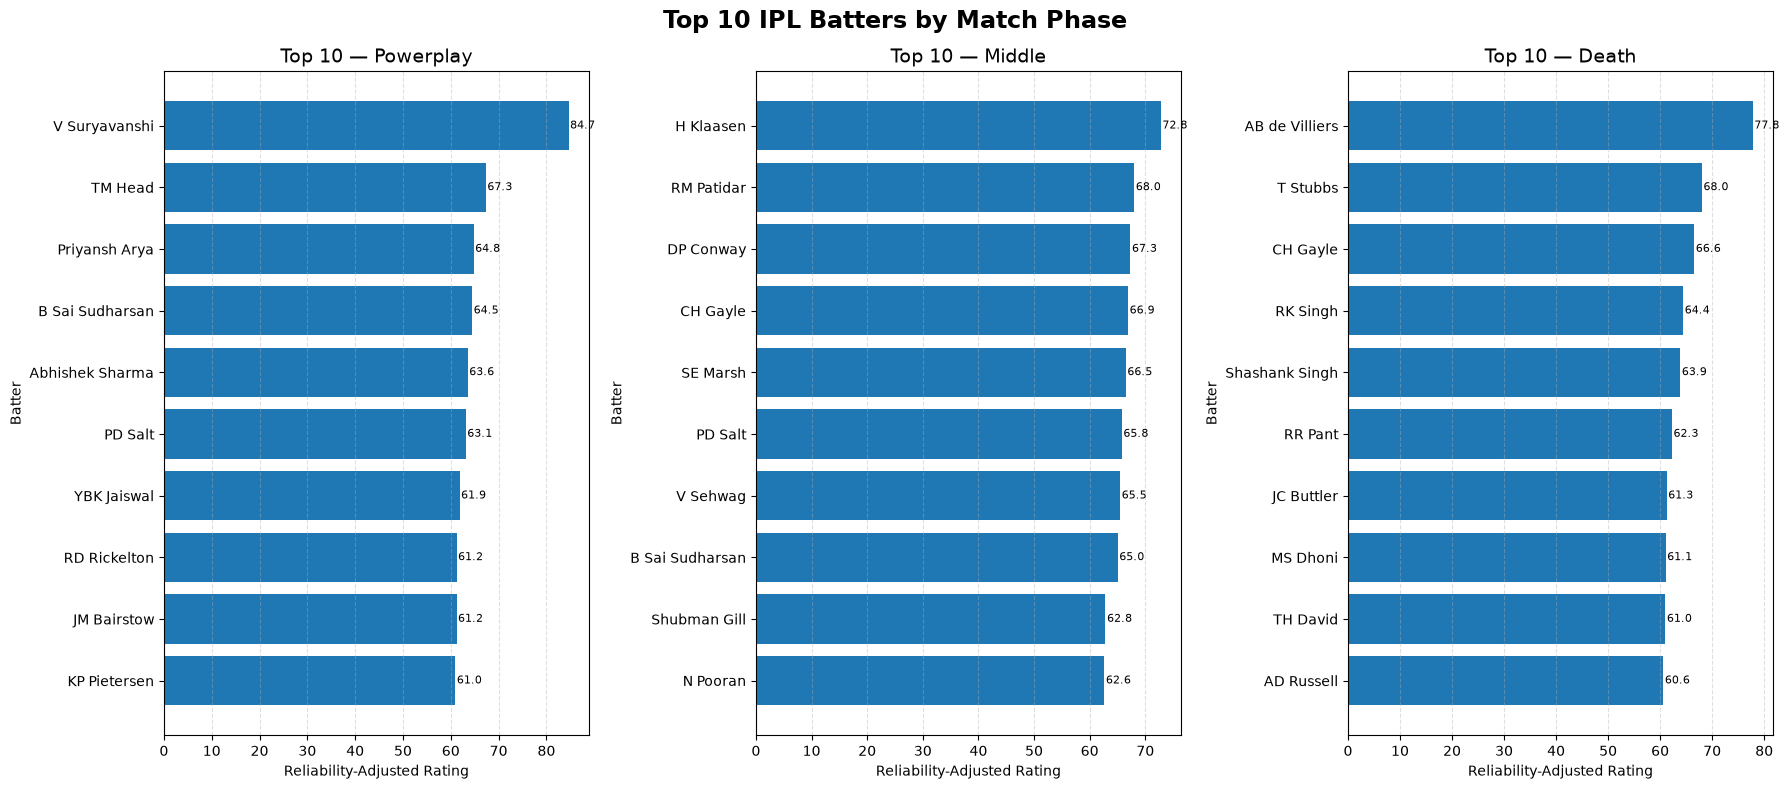

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

phases = ["Powerplay", "Middle", "Death"]

for ax, phase in zip(axes, phases):

    phase_data = (
        top_10_by_phase[
            top_10_by_phase["phase"] == phase
        ]
        .sort_values("reliability_adjusted_rating")
    )

    bars = ax.barh(
        phase_data["batter"],
        phase_data["reliability_adjusted_rating"]
    )

    ax.set_title(f"Top 10 — {phase}", fontsize=14)
    ax.set_xlabel("Reliability-Adjusted Rating")
    ax.set_ylabel("Batter")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    for bar in bars:
        ax.text(
            bar.get_width() + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}",
            va="center",
            fontsize=8
        )

plt.suptitle(
    "Top 10 IPL Batters by Match Phase",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

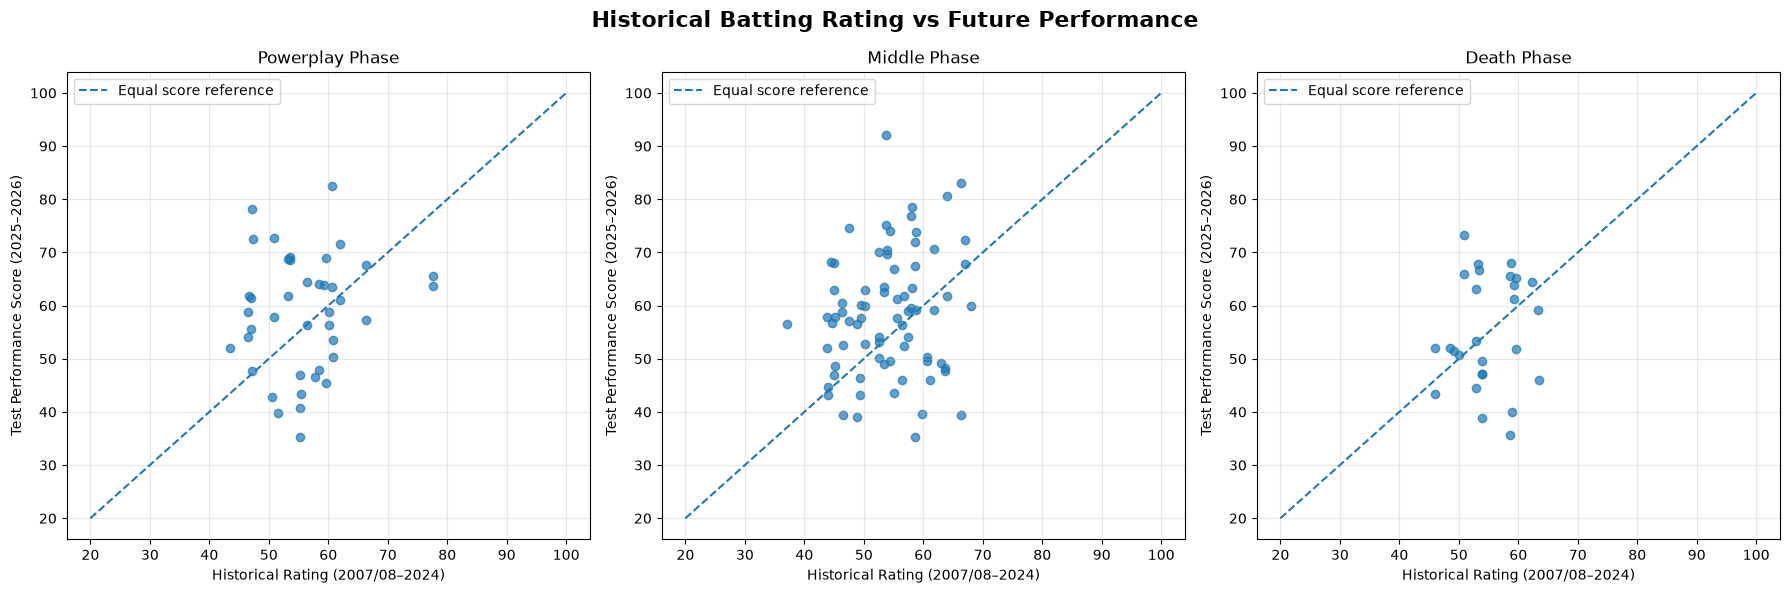

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

phases = ["Powerplay", "Middle", "Death"]

for ax, phase in zip(axes, phases):

    phase_data = matched_validation[
        matched_validation["phase"] == phase
    ]

    ax.scatter(
        phase_data["training_batting_rating"],
        phase_data["test_performance_score"],
        alpha=0.7
    )

    # Reference line: equal historical and test scores
    ax.plot(
        [20, 100],
        [20, 100],
        linestyle="--",
        label="Equal score reference"
    )

    ax.set_title(f"{phase} Phase")
    ax.set_xlabel("Historical Rating (2007/08–2024)")
    ax.set_ylabel("Test Performance Score (2025–2026)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Historical Batting Rating vs Future Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

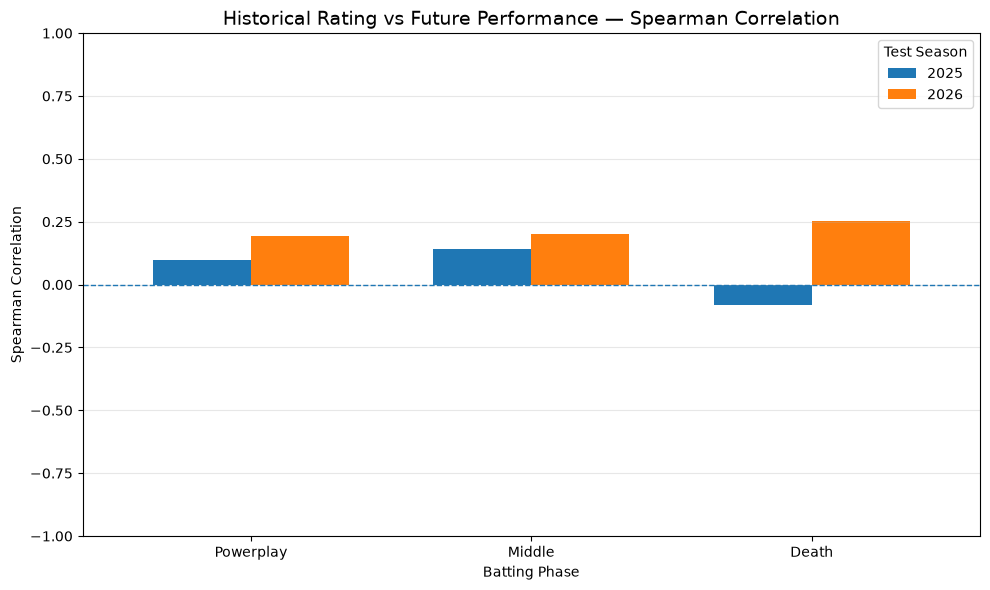

In [55]:
correlation_pivot = correlation_results.pivot(
    index="phase",
    columns="season",
    values="spearman_correlation"
)

correlation_pivot = correlation_pivot.reindex(
    ["Powerplay", "Middle", "Death"]
)

ax = correlation_pivot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Historical Rating vs Future Performance — Spearman Correlation",
    fontsize=14
)

ax.set_xlabel("Batting Phase")
ax.set_ylabel("Spearman Correlation")
ax.set_ylim(-1, 1)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Test Season")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

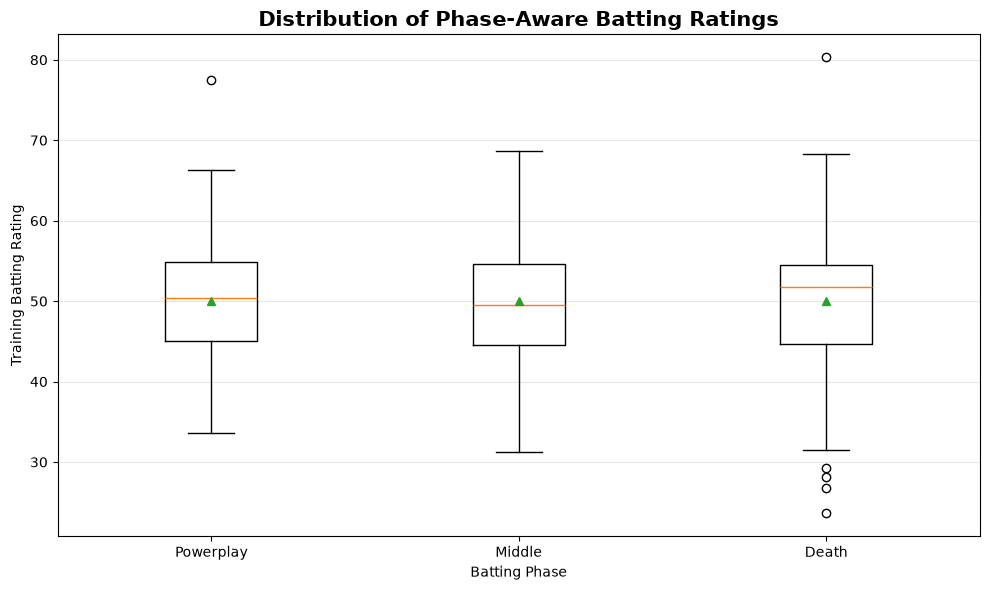

In [56]:
plt.figure(figsize=(10, 6))

rating_data = [
    train_rating_data[
        train_rating_data["phase"] == phase
    ]["training_batting_rating"].dropna()
    for phase in ["Powerplay", "Middle", "Death"]
]

plt.boxplot(
    rating_data,
    tick_labels=["Powerplay", "Middle", "Death"],
    showmeans=True
)

plt.title(
    "Distribution of Phase-Aware Batting Ratings",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Batting Phase")
plt.ylabel("Training Batting Rating")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

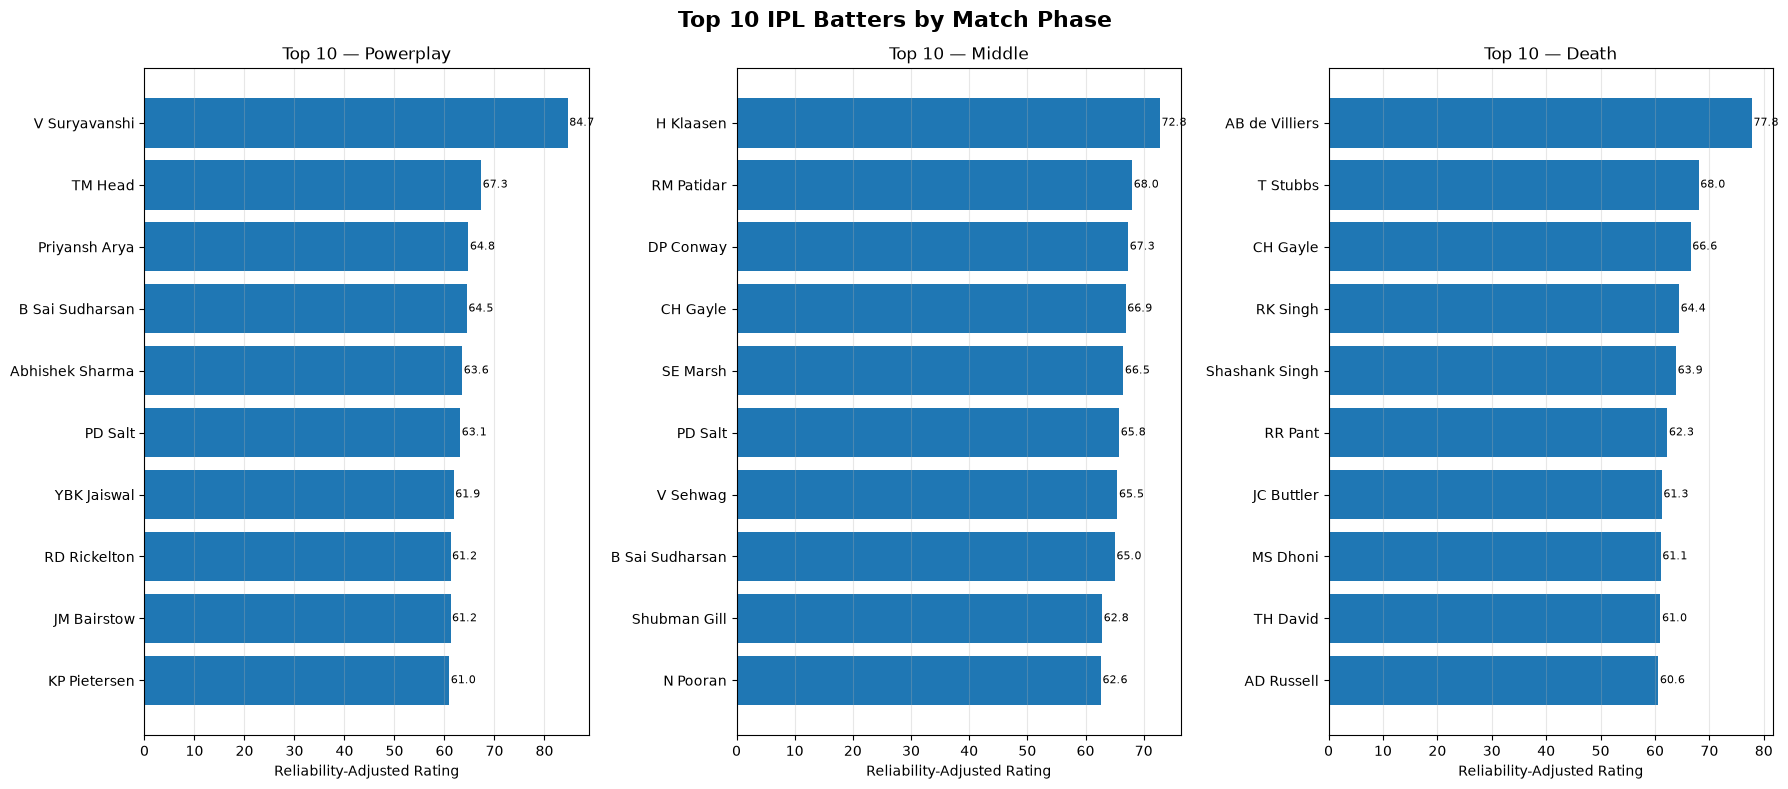

Chart saved successfully!
Location: C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\Charts\top_10_batters_by_phase.png


In [57]:
output_folder = project_folder / "Outputs"
chart_folder = output_folder / "Charts"

chart_folder.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, phase in zip(axes, ["Powerplay", "Middle", "Death"]):

    phase_data = (
        top_10_by_phase[
            top_10_by_phase["phase"] == phase
        ]
        .sort_values("reliability_adjusted_rating")
    )

    bars = ax.barh(
        phase_data["batter"],
        phase_data["reliability_adjusted_rating"]
    )

    ax.set_title(f"Top 10 — {phase}")
    ax.set_xlabel("Reliability-Adjusted Rating")
    ax.grid(axis="x", alpha=0.3)

    for bar in bars:
        ax.text(
            bar.get_width() + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}",
            va="center",
            fontsize=8
        )

fig.suptitle(
    "Top 10 IPL Batters by Match Phase",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    chart_folder / "top_10_batters_by_phase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print("Location:", chart_folder / "top_10_batters_by_phase.png")

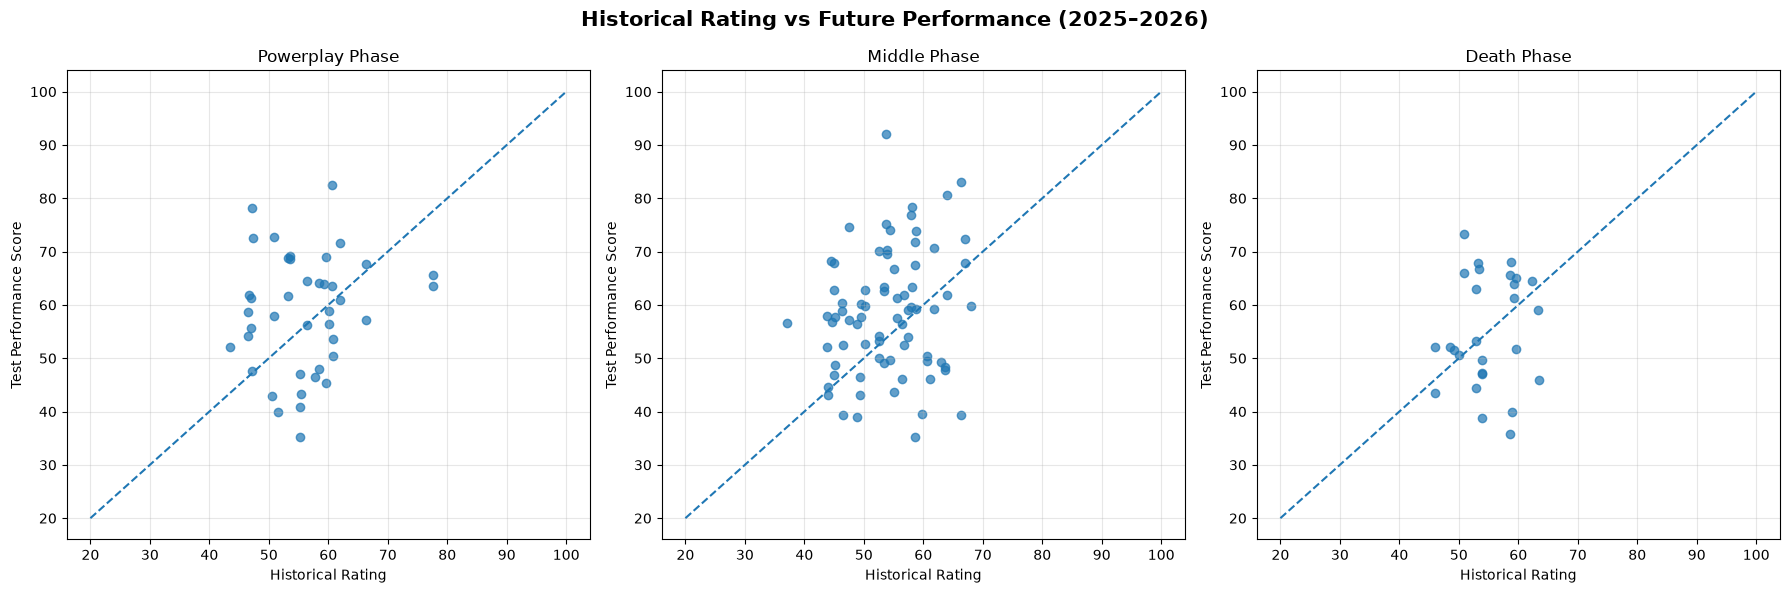

Second chart saved successfully!


In [58]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, phase in zip(axes, ["Powerplay", "Middle", "Death"]):

    phase_data = matched_validation[
        matched_validation["phase"] == phase
    ]

    ax.scatter(
        phase_data["training_batting_rating"],
        phase_data["test_performance_score"],
        alpha=0.7
    )

    ax.plot([20, 100], [20, 100], linestyle="--")

    ax.set_title(f"{phase} Phase")
    ax.set_xlabel("Historical Rating")
    ax.set_ylabel("Test Performance Score")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Historical Rating vs Future Performance (2025–2026)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    chart_folder / "historical_vs_future_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Second chart saved successfully!")

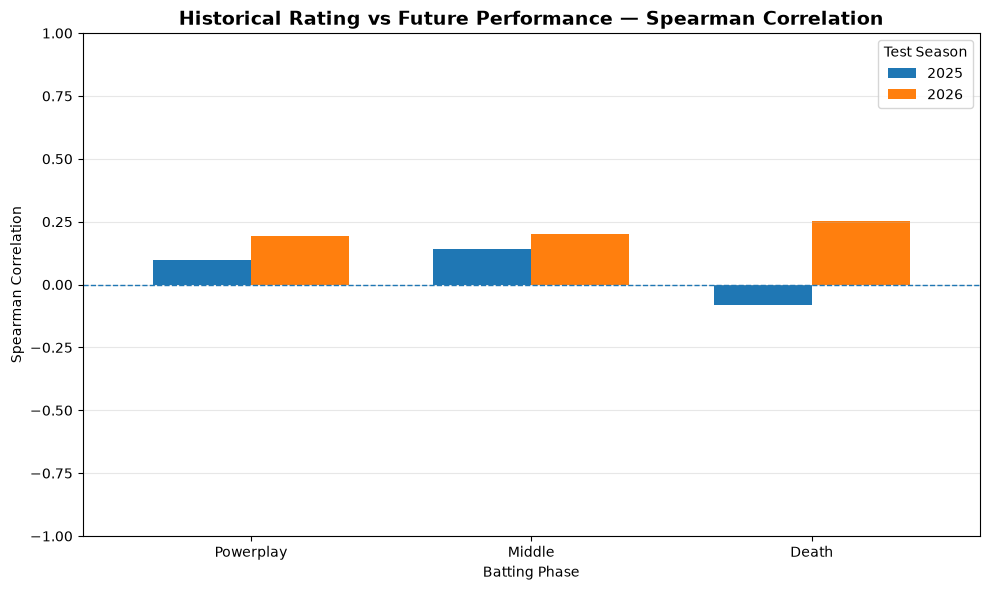

Third chart saved successfully!


In [59]:
correlation_pivot = correlation_results.pivot(
    index="phase",
    columns="season",
    values="spearman_correlation"
).reindex(["Powerplay", "Middle", "Death"])

fig, ax = plt.subplots(figsize=(10, 6))

correlation_pivot.plot(
    kind="bar",
    ax=ax,
    width=0.7
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Historical Rating vs Future Performance — Spearman Correlation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Batting Phase")
ax.set_ylabel("Spearman Correlation")
ax.set_ylim(-1, 1)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Test Season")

plt.xticks(rotation=0)
plt.tight_layout()

fig.savefig(
    chart_folder / "spearman_correlation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Third chart saved successfully!")

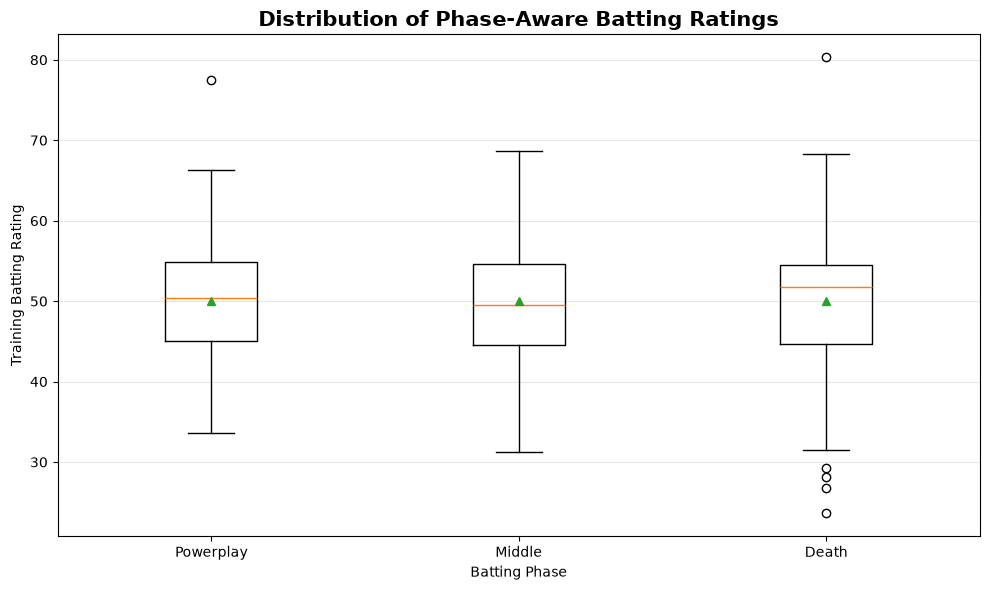

Fourth chart saved successfully!
All four visualizations have been exported.
Chart folder: C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Outputs\Charts


In [60]:
rating_data = [
    train_rating_data[
        train_rating_data["phase"] == phase
    ]["training_batting_rating"].dropna()
    for phase in ["Powerplay", "Middle", "Death"]
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    rating_data,
    tick_labels=["Powerplay", "Middle", "Death"],
    showmeans=True
)

ax.set_title(
    "Distribution of Phase-Aware Batting Ratings",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Batting Phase")
ax.set_ylabel("Training Batting Rating")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    chart_folder / "phase_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fourth chart saved successfully!")
print("All four visualizations have been exported.")
print("Chart folder:", chart_folder)

In [61]:
print("PHASE-AWARE PLAYER RATING — FINAL CHECK")
print("=" * 45)

print("\nDataset shapes:")
print("Full IPL dataset:", ipl.shape)
print("Training batting ratings:", train_rating_data.shape)
print("Test performance data:", test_rating_data.shape)
print("Temporal validation data:", validation_data.shape)

print("\nValidation summary:")
display(combined_validation_results.round(3))

print("\nSaved output files:")

required_files = [
    output_folder / "phase_aware_batting_ratings.csv",
    output_folder / "phase_aware_temporal_validation.csv",
    output_folder / "temporal_validation_correlations.csv",
    output_folder / "combined_validation_summary.csv",
    chart_folder / "top_10_batters_by_phase.png",
    chart_folder / "historical_vs_future_performance.png",
    chart_folder / "spearman_correlation_comparison.png",
    chart_folder / "phase_rating_distribution.png"
]

for file in required_files:
    status = "FOUND" if file.exists() else "MISSING"
    print(f"{status}: {file.name}")

print("\nFinal check completed.")

PHASE-AWARE PLAYER RATING — FINAL CHECK

Dataset shapes:
Full IPL dataset: (295732, 36)
Training batting ratings: (299, 23)
Test performance data: (233, 23)
Temporal validation data: (233, 25)

Validation summary:


,group,players_evaluated,spearman_correlation,spearman_p_value,pearson_correlation,pearson_p_value
0,Overall,143,0.141,0.093,0.146,0.082
1,Powerplay,41,0.139,0.384,0.127,0.430
2,Middle,75,0.170,0.145,0.172,0.141
3,Death,27,0.029,0.887,0.116,0.566



Saved output files:
FOUND: phase_aware_batting_ratings.csv
FOUND: phase_aware_temporal_validation.csv
FOUND: temporal_validation_correlations.csv
FOUND: combined_validation_summary.csv
FOUND: top_10_batters_by_phase.png
FOUND: historical_vs_future_performance.png
FOUND: spearman_correlation_comparison.png
FOUND: phase_rating_distribution.png

Final check completed.
